In [1]:
import numpy as np
import matplotlib.pyplot as plt

import pywt

# Add files up one level to the path
import sys
sys.path.append("../..")

import scipy.sparse as sps
from scipy.fft import dct, idct
import jlinops

import sys
import os

from wavelets import WaveletTransformOperator2D

import jlinops




from mpl_toolkits.axes_grid1 import make_axes_locatable
from matplotlib.ticker import FormatStrFormatter

import matplotlib as mpl
from mpl_toolkits.axes_grid1 import make_axes_locatable
import matplotlib.gridspec as gridspec
# mpl.rcParams['text.usetex'] = True
# mpl.rc('text.latex', preamble=r'\usepackage{amsmath}')

# Define the custom style with RGB color values
custom_style = {
    "axes.prop_cycle": plt.cycler(color=[(106/255, 192/255, 205/255),  # blue - C0
                                         (235/255, 186/255, 63/255),  # gold - C1
                                         (172/255, 46/255, 55/255),  # red - C2
                                         (32/255, 82/255, 145/255),  # dark blue - C3
                                         (83/255, 165/255, 106/255),  # green - C4
                                         (239/255, 145/255, 75/255),  # orange - C5
                                         (208/255, 92/255, 89/255),  # pink - C6
                                         (80/255, 67/255, 157/255),  # purple - C7
                                         (82/255, 82/255, 82/255),  # gray - C8
                                         (53/255, 53/255, 53/255),  # charcoal - C9
                                         (30/255, 27/255, 28/255), # black - C10  
                                         ]) 
}
plt.rc('axes', prop_cycle=custom_style['axes.prop_cycle'])



from msolver import IASGKS, MM2019GKS, VanillaGKS # 2019 weights
from fsolver import MM2019FGK, IASFGK # 2019 weights
from f2019solver import MM2019FGK2019, IASFGK2019 # 2019 iterative method (ends in 2019)
from pgkbsolver import MM2019GKB, IASGKB

# Setup toy problem

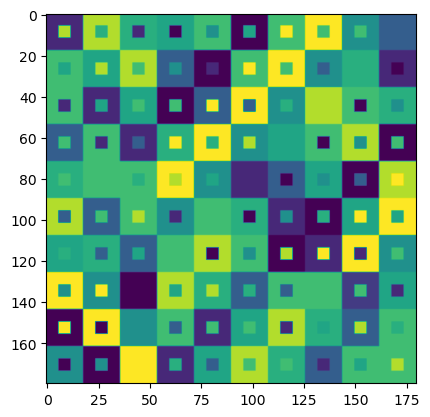

In [2]:
image = jlinops.graecolatinsquare(which=10)
image = image[::5,::5]
plt.imshow(image)

In [3]:
np.log2(256)

8.0

In [4]:
image.shape

(180, 180)

In [5]:
image = jlinops.graecolatinsquare(which=10)
image = image[::3,::3]
image = image[:256,:256]
#image = jlinops.cameraman()
img_shape = image.shape
ground_truth = image.flatten()

A = jlinops.Gaussian2DBlurOperator(img_shape, blur_sigma=2.0, mode="reflect")
#A = WaveletTransformOperator2D(img_shape, wavelet="haar", level=3)
b_true = A @ ground_truth
noise_level_sigma = 0.03
noise_vec = np.random.normal(size=A.shape[0])
noise_vec /= np.linalg.norm(noise_vec)
noise_vec *= noise_level_sigma*np.linalg.norm(b_true)
noise_var = ( (noise_level_sigma*np.linalg.norm(b_true) )**2 ) / A.shape[0]
noise_sigma = np.sqrt(noise_var)
b = b_true + noise_vec
naive_recon = A.T @ b

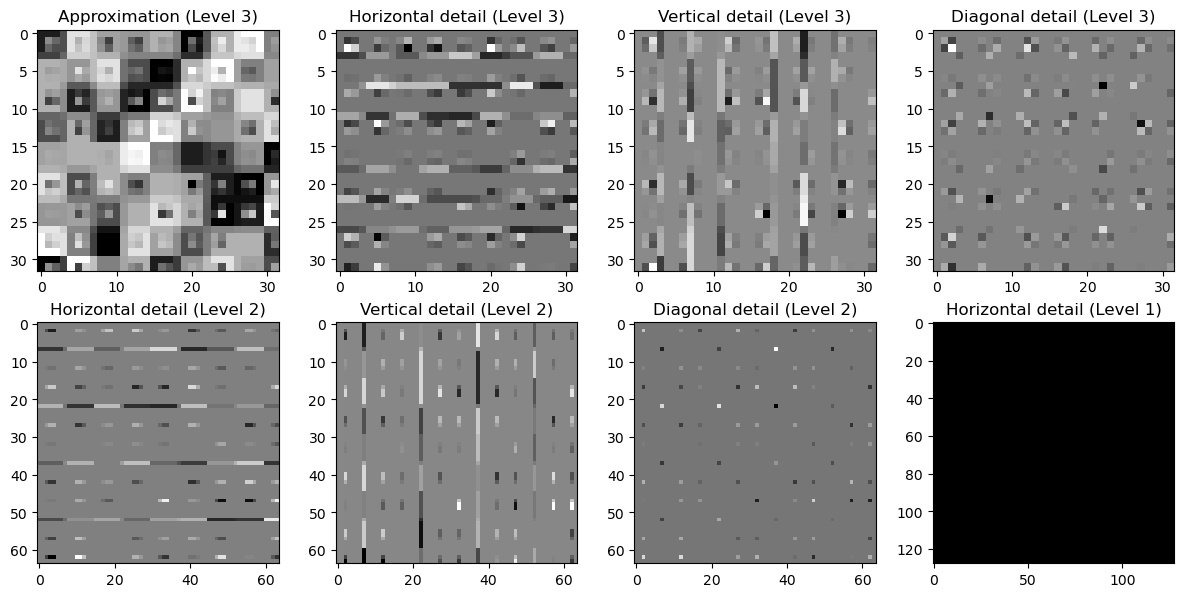

In [6]:
# Create a sample 2D image (e.g., 256x256 random matrix)

# Perform 2D wavelet decomposition using Haar wavelet, with 3 levels
coeffs = pywt.wavedec2(image, 'haar', level=3)

# coeffs is a list containing the approximation coefficients and detail coefficients
# The first element of coeffs is the approximation coefficient at level 3
# The subsequent elements are tuples of detail coefficients (horizontal, vertical, diagonal) for each level

# Extract the approximation coefficients at the final level (level 3)
cA3 = coeffs[0]

# Extract the detail coefficients (cH, cV, cD) for each level
(cH3, cV3, cD3), (cH2, cV2, cD2), (cH1, cV1, cD1) = coeffs[1:]

# Plotting the approximation and detail coefficients for visualization
fig, ax = plt.subplots(2, 4, figsize=(12, 6))

# Level 3 coefficients
ax[0, 0].imshow(cA3, cmap='gray')
ax[0, 0].set_title('Approximation (Level 3)')

ax[0, 1].imshow(cH3, cmap='gray')
ax[0, 1].set_title('Horizontal detail (Level 3)')

ax[0, 2].imshow(cV3, cmap='gray')
ax[0, 2].set_title('Vertical detail (Level 3)')

ax[0, 3].imshow(cD3, cmap='gray')
ax[0, 3].set_title('Diagonal detail (Level 3)')

# Level 2 coefficients
ax[1, 0].imshow(cH2, cmap='gray')
ax[1, 0].set_title('Horizontal detail (Level 2)')

ax[1, 1].imshow(cV2, cmap='gray')
ax[1, 1].set_title('Vertical detail (Level 2)')

ax[1, 2].imshow(cD2, cmap='gray')
ax[1, 2].set_title('Diagonal detail (Level 2)')

# Level 1 coefficients
ax[1, 3].imshow(cH1, cmap='gray')
ax[1, 3].set_title('Horizontal detail (Level 1)')

# Adjust layout and show the plot
plt.tight_layout()
plt.show()


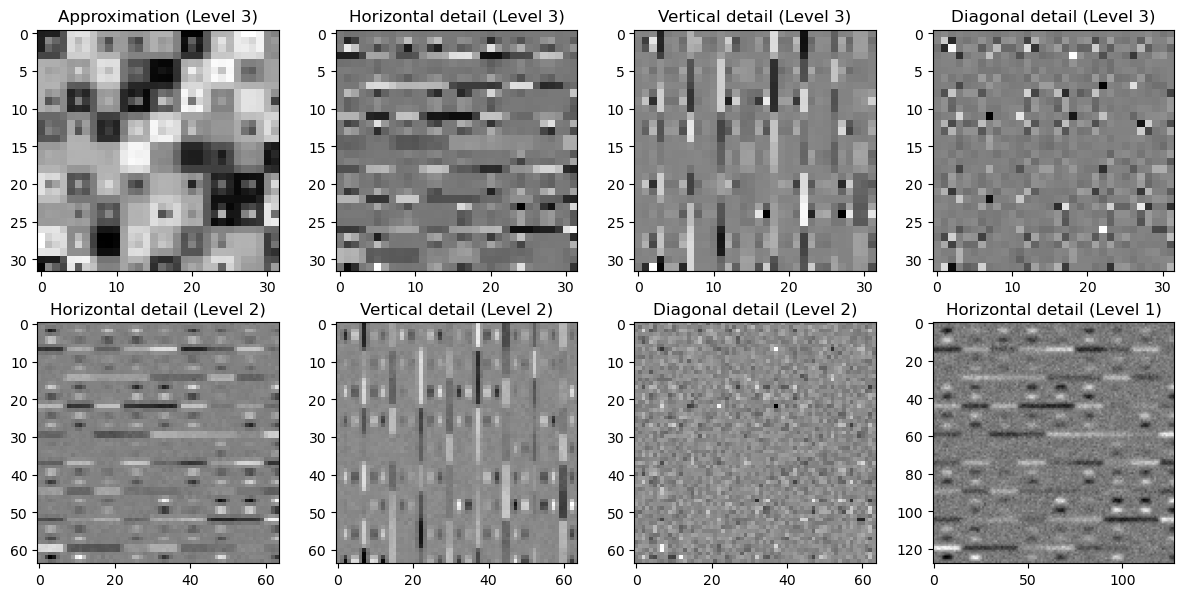

In [7]:
# Create a sample 2D image (e.g., 256x256 random matrix)

# Perform 2D wavelet decomposition using Haar wavelet, with 3 levels
coeffs = pywt.wavedec2(b.reshape(img_shape), 'haar', level=3)

# coeffs is a list containing the approximation coefficients and detail coefficients
# The first element of coeffs is the approximation coefficient at level 3
# The subsequent elements are tuples of detail coefficients (horizontal, vertical, diagonal) for each level

# Extract the approximation coefficients at the final level (level 3)
cA3 = coeffs[0]

# Extract the detail coefficients (cH, cV, cD) for each level
(cH3, cV3, cD3), (cH2, cV2, cD2), (cH1, cV1, cD1) = coeffs[1:]

# Plotting the approximation and detail coefficients for visualization
fig, ax = plt.subplots(2, 4, figsize=(12, 6))

# Level 3 coefficients
ax[0, 0].imshow(cA3, cmap='gray')
ax[0, 0].set_title('Approximation (Level 3)')

ax[0, 1].imshow(cH3, cmap='gray')
ax[0, 1].set_title('Horizontal detail (Level 3)')

ax[0, 2].imshow(cV3, cmap='gray')
ax[0, 2].set_title('Vertical detail (Level 3)')

ax[0, 3].imshow(cD3, cmap='gray')
ax[0, 3].set_title('Diagonal detail (Level 3)')

# Level 2 coefficients
ax[1, 0].imshow(cH2, cmap='gray')
ax[1, 0].set_title('Horizontal detail (Level 2)')

ax[1, 1].imshow(cV2, cmap='gray')
ax[1, 1].set_title('Vertical detail (Level 2)')

ax[1, 2].imshow(cD2, cmap='gray')
ax[1, 2].set_title('Diagonal detail (Level 2)')

# Level 1 coefficients
ax[1, 3].imshow(cH1, cmap='gray')
ax[1, 3].set_title('Horizontal detail (Level 1)')

# Adjust layout and show the plot
plt.tight_layout()
plt.show()


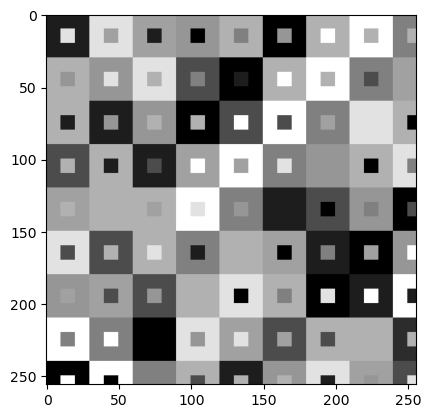

In [8]:
plt.imshow(image, cmap="gray")
plt.show()

In [9]:
b.shape

(65536,)

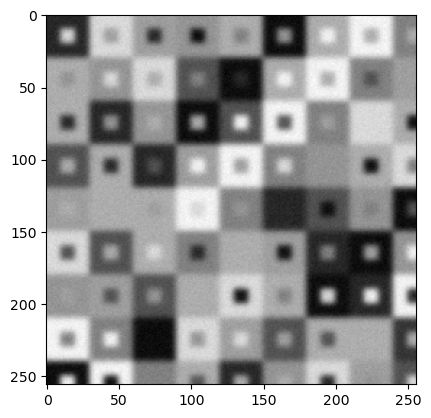

In [10]:
plt.imshow(b.reshape(img_shape), cmap="gray")
plt.show()

# Set up prior

In [55]:
# This can be figured out later
# mask = np.zeros(Lpre.shape[0])
# mask[ Lpre.detail_indices ] = 1
# P = jlinops.Subsampling1DOperator(mask)
#L = P @ Lpre

L = WaveletTransformOperator2D(img_shape, wavelet="haar", level=3)
K = None
Lpinv_factory = lambda wr: L.T @ jlinops.MatrixLinearOperator(sps.diags(1.0/wr))
Lpinv_factory2 = lambda wr: jlinops.MatrixLinearOperator(sps.diags(1.0/wr))

In [56]:
image.shape

(256, 256)

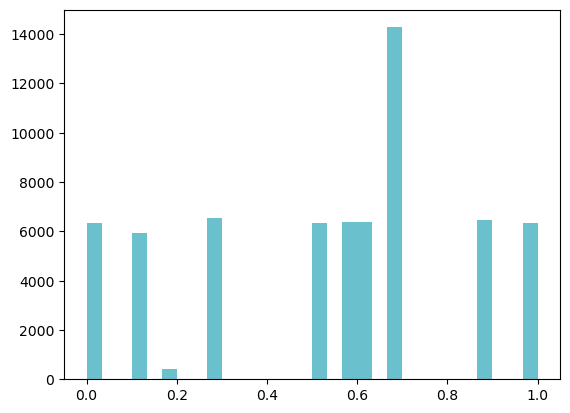

In [57]:
plt.hist(ground_truth, bins=30)
plt.show()

In [58]:
# Set method
method = "dp"

xker = None


# Weight params
q = 1.0

mm_weight_params_2019 = {
    "tau1": 1e-10,
    "tau2": 1e-16,
    "q": q,
}

ias_weight_params = {
    "hyperpr_r": -1,
    "hyperpr_beta": 1,
}

### Build solvers

# GKS solver
gks_solver = VanillaGKS(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K, img_shape=img_shape)

# MM solvers
mmgks_solver = MM2019GKS(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K, img_shape=img_shape)
mmfkx_solver = MM2019FGK(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K, img_shape=img_shape)
mmfk2019_solver = MM2019FGK2019(A, L, L.T, b, noise_var=noise_var, K=K, img_shape=img_shape)
mmgkb_solver = MM2019GKB(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K, img_shape=img_shape)

# IAS solvers
iasgks_solver = IASGKS(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K, img_shape=img_shape)
iasfkx_solver = IASFGK(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K, img_shape=img_shape)
iasfk2019_solver = IASFGK2019(A, L, L.T, b, noise_var=noise_var, K=K, img_shape=img_shape)
iasgkb_solver = IASGKB(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K, img_shape=img_shape)

In [59]:
# L.shape

In [60]:
# len(ground_truth)

In [61]:
# L.matvec(ground_truth)

In [62]:
n_its = 150


# GKS
vdata = gks_solver.solve(n_iter=n_its, init_dim=5, x0=None, lambdah0=1e0, lambdah_min=1e-7, lambdah_max=1e7,
                                    regparam=method, x_true=ground_truth, weight_params={},
                                    regparam_kwargs={"eta":1.01},  xker=xker)

# MM PS-GKS
mmpsgkspdata = mmgks_solver.solve_with_priorconditioning(n_iter=n_its, init_dim=5, x0=vdata["x"], lambdah0=vdata["lambdah"], lambdah_min=1e-7, lambdah_max=1e7,
                                                 regparam=method, x_true=ground_truth, weight_params=mm_weight_params_2019, 
                                                 regparam_kwargs={"eta":1.01})

# MM S-GKS
mmsgksdata = mmgks_solver.solve(n_iter=n_its, init_dim=5, x0=vdata["x"], lambdah0=vdata["lambdah"], lambdah_min=1e-7, lambdah_max=1e7,
                                    regparam=method, x_true=ground_truth, weight_params=mm_weight_params_2019,
                                    regparam_kwargs={"eta":1.01}, min_dim=None, max_dim=None, xker=xker)


# MM FKX
mmfkxdata = mmfkx_solver.solve(n_iter=n_its, x0=None, lambdah0=None,
                                                 regparam=method, x_true=ground_truth, ksparsity=None, weight_params=mm_weight_params_2019, refresh_basis=False, lambdah_min=1e-7, lambdah_max=1e7,
                                                #  regparam_kwargs={"eta":1.01},
                                                #  lambdah_min=1e-7, lambdah_max=1e7,
                                                #  init_dim=5
                                                 )

# MM FK2019 I
mmfk2019Idata = mmfk2019_solver.solve(n_iter=n_its, mode="I", x0=None, lambdah0=None,
                                                 regparam=method, x_true=ground_truth, ksparsity=None, weight_params=mm_weight_params_2019, refresh_basis=False, lambdah_min=1e-7, lambdah_max=1e7,
                                                #  regparam_kwargs={"eta":1.01},
                                                #  lambdah_min=1e-7, lambdah_max=1e7,
                                                #  init_dim=5
                                                 )

# MM FK2019 R
mmfk2019Rdata = mmfk2019_solver.solve(n_iter=n_its, x0=None, mode="R", lambdah0=None,
                                                 regparam=method, x_true=ground_truth, ksparsity=None, weight_params=mm_weight_params_2019, refresh_basis=False, lambdah_min=1e-7, lambdah_max=1e7,
                                                #  regparam_kwargs={"eta":1.01},
                                                #  lambdah_min=1e-7, lambdah_max=1e7,
                                                #  init_dim=5
                                                 )

# MM FK2019 W (IRW-FLSQR)
mmfk2019Wdata = mmfk2019_solver.solve(n_iter=n_its, x0=None, mode="W", lambdah0=None,
                                                 regparam=method, x_true=ground_truth, ksparsity=None, weight_params=mm_weight_params_2019, refresh_basis=False, lambdah_min=1e-7, lambdah_max=1e7,
                                                #  regparam_kwargs={"eta":1.01},
                                                #  lambdah_min=1e-7, lambdah_max=1e7,
                                                #  init_dim=5
                                                 )


# MM GKB 
mmgkbdata = mmgkb_solver.solve(n_iter=n_its, x0=None, lambdah0=None,
                                                 regparam=method, x_true=ground_truth, ksparsity=None, weight_params=mm_weight_params_2019, lambdah_min=1e-7, lambdah_max=1e7
                                                #  regparam_kwargs={"eta":1.01},
                                                #  lambdah_min=1e-7, lambdah_max=1e7,
                                                #  init_dim=5
                                                 )

print("Finished P-GKB")







# IAS PS-GKS
iaspsgkspdata = iasgks_solver.solve_with_priorconditioning(n_iter=n_its, init_dim=5, x0=vdata["x"], lambdah0=vdata["lambdah"], lambdah_min=1e-7, lambdah_max=1e7,
                                                 regparam=method, x_true=ground_truth, weight_params=ias_weight_params, 
                                                 regparam_kwargs={"eta":1.01})

# IAS S-GKS
iassksdata = iasgks_solver.solve(n_iter=n_its, init_dim=5, x0=vdata["x"], lambdah0=vdata["lambdah"], lambdah_min=1e-7, lambdah_max=1e7,
                                    regparam=method, x_true=ground_truth, weight_params=ias_weight_params,
                                    regparam_kwargs={"eta":1.01}, min_dim=None, max_dim=None, xker=xker)


# IAS FKX
iasfkdata = iasfkx_solver.solve(n_iter=n_its, x0=None, lambdah0=None,
                                                 regparam=method, x_true=ground_truth, ksparsity=None, weight_params=ias_weight_params, refresh_basis=False, lambdah_min=1e-7, lambdah_max=1e7,
                                                #  regparam_kwargs={"eta":1.01},
                                                #  lambdah_min=1e-7, lambdah_max=1e7,
                                                #  init_dim=5
                                                 )

# IAS FK2019 I
iasfk2019Idata = iasfk2019_solver.solve(n_iter=n_its, mode="I", x0=None, lambdah0=None,
                                                 regparam=method, x_true=ground_truth, ksparsity=None, weight_params=ias_weight_params, refresh_basis=False, lambdah_min=1e-7, lambdah_max=1e7,
                                                #  regparam_kwargs={"eta":1.01},
                                                #  lambdah_min=1e-7, lambdah_max=1e7,
                                                #  init_dim=5
                                                 )

# IAS FK2019 R
mmfk2019Rdata = iasfk2019_solver.solve(n_iter=n_its, x0=None, mode="R", lambdah0=None,
                                                 regparam=method, x_true=ground_truth, ksparsity=None, weight_params=ias_weight_params, refresh_basis=False, lambdah_min=1e-7, lambdah_max=1e7,
                                                #  regparam_kwargs={"eta":1.01},
                                                #  lambdah_min=1e-7, lambdah_max=1e7,
                                                #  init_dim=5
                                                 )

# IAS FK2019 W (IRW-FLSQR)
iasfk2019Wdata = iasfk2019_solver.solve(n_iter=n_its, x0=None, mode="W", lambdah0=None,
                                                 regparam=method, x_true=ground_truth, ksparsity=None, weight_params=ias_weight_params, refresh_basis=False, lambdah_min=1e-7, lambdah_max=1e7,
                                                #  regparam_kwargs={"eta":1.01},
                                                #  lambdah_min=1e-7, lambdah_max=1e7,
                                                #  init_dim=5
                                                 )


# MM GKB 
iasgkbdata = iasgkb_solver.solve(n_iter=n_its, x0=None, lambdah0=None,
                                                 regparam=method, x_true=ground_truth, ksparsity=None, weight_params=ias_weight_params, lambdah_min=1e-7, lambdah_max=1e7
                                                #  regparam_kwargs={"eta":1.01},
                                                #  lambdah_min=1e-7, lambdah_max=1e7,
                                                #  init_dim=5
                                                 )




1e-07
10.435070261431461
19.003639885757373
23.272510526209977
25.534978699882195
26.683984297078084
27.326138441002982
27.8598832270395
28.249299466076145
28.515617606374995
28.724017776155257
28.87770495477441
28.978413539622462
29.047115228751434
29.102559836990235
29.147263176137464
29.179779881206763
29.203159782972357
29.218956349511878
29.229403665114116
29.23659953705316
29.24133595850949
29.244534346534188
29.24697042055994
29.24875264823141
29.250132623657585
29.251082013248297
29.251731154992935
29.25220509314576
29.25253003829386
29.25273892427182
29.25288474705984
29.252980585392084
29.253047620429893
29.253096527002633
29.25313045796828
29.253153907461396
29.253171072582628
29.253182702481304
29.253190738500948
29.253196263149967
29.253199840015032
29.253202396390794
29.253204270253722
29.253205598324918
29.253206520083697
29.253207119708897
29.253207552141124
29.253207837922915
29.253208031553356
29.253208156096047
29.25320824370305
29.253208303622063
29.253208347745172


1e-07


/Users/jonathanlindbloom/Github/IRLS_prec_GSBL/tests/2d_blur_wavelets/../../msolver.py:800: UserWarning: Inequality is NOT satisfied, no solution to the DP problem...
  warnings.warn("Inequality is NOT satisfied, no solution to the DP problem...", UserWarning)


1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
6.304060250175528
8.565280637476791
10.258824840364067
11.50318302846973
12.574012111621457
13.474156682921164
14.184532504446265
14.730715194599282
15.2662836791336
15.758173228456153
16.23182370238219
16.64787270389244
17.01478423887767
17.34856092790008
17.652808245725552
17.92064262146602
18.14575141454687
18.342188571846076
18.545537969669656
18.74582124579104
18.907652986898327
19.066462316891528
19.214742511235368
19.358114378203556
19.485338373688293
19.611118545967777
19.703722950553487
19.799893724574346
19.924426404381578
20.03332745477874
20.150832073349193
20.246719857128422
20.34181273996622
20.433433136404176
20.503073071149075
20.57639792325067
2

62.16535577220947
25.337002375582077
36.173029741592416
27.454922400828316
27.979780654766714
22.17539090715019
21.9417203519382
19.79148176693683
19.173924340987046
19.208881804531146
15.968666307361683
18.604600504082885
16.41766227850661
17.75867606162449
17.285152431455607
18.497404243879817
18.285184819795965
18.442219721350654
18.66940550436964
18.59418543625748
18.197374768117587
19.182403355491445
19.32220472636877
18.98132022842028
18.658275176156305
18.546118119916404
18.342640588187376
18.193764138790936
18.75289621830965
18.45646437807726
18.485105009354793
18.339378597736186
18.33860207189192
18.483380506510382
18.01158051678727
18.073971217244097
18.078393126132376
18.06055378427055
17.78887368820699
17.862950408123247
17.94149719674337
18.049225402546906
17.757717746568268
17.501880156384114
17.61460702560829
17.546874692508197
17.438589760595185
17.36320752906717
17.046342625652855
16.51137525339216
16.324361362986092
15.663464311946845
14.533419329596992
13.55113027425

...

1e-07


generating basis...: 100%|██████████| 149/149 [00:02<00:00, 57.77it/s]


11.701300209976484


generating basis...: 100%|██████████| 150/150 [00:02<00:00, 54.10it/s]

88.70333732419712


In [117]:
np.sqrt(90151)

300.251561194942

# Plots

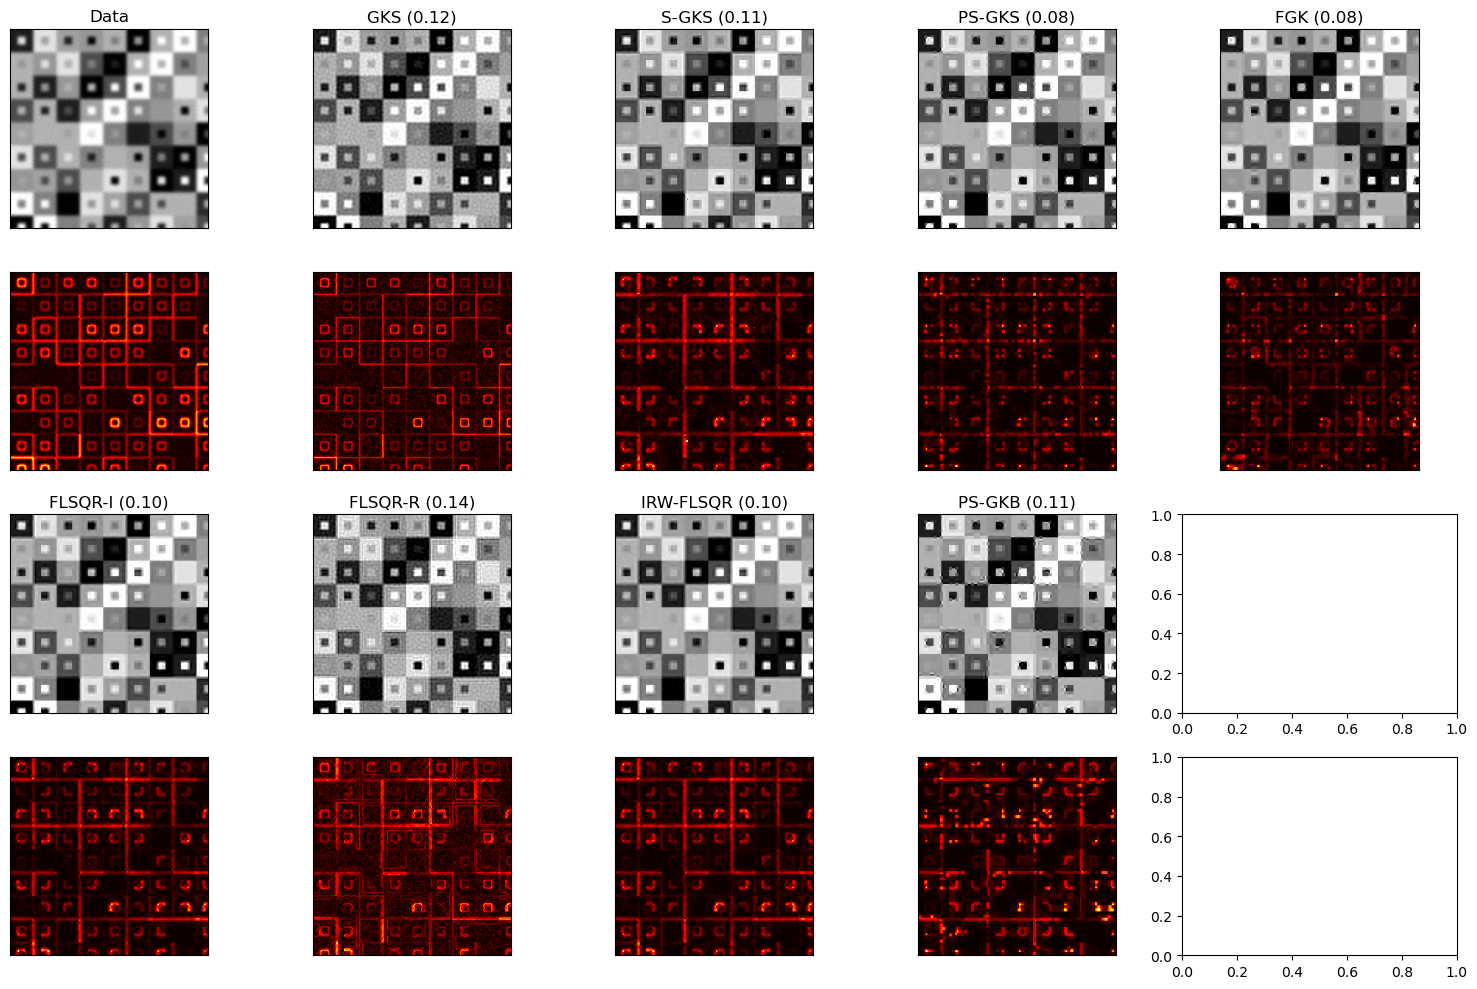

In [69]:
err_cmap = "hot"

vbound = 0.6

fig, axs = plt.subplots(4,5,figsize=(15.3,10))


# Observed
axs[0,0].imshow(b.reshape(img_shape), cmap="gray", vmin=0, vmax=1)
axs[0,0].set_title("Data")
axs[0,0].set_xticks([])
axs[0,0].set_yticks([])

axs[1,0].imshow(np.abs( b.reshape(img_shape) - ground_truth.reshape(img_shape) ), cmap=err_cmap, vmin=0, vmax=vbound)
axs[1,0].set_xticks([])
axs[1,0].set_yticks([])



# Tikhonov
axs[0,1].imshow(vdata["x"].reshape(img_shape), cmap="gray", vmin=0, vmax=1)
rre = vdata["rre_history"][-1]
axs[0,1].set_title(f"GKS ({rre:.2f})")
axs[0,1].set_xticks([])
axs[0,1].set_yticks([])

axs[1,1].imshow(np.abs( vdata["x"].reshape(img_shape) - ground_truth.reshape(img_shape) ), cmap=err_cmap, vmin=0, vmax=vbound)
axs[1,1].set_xticks([])
axs[1,1].set_yticks([])


# S-GKS
axs[0,2].imshow(mmsgksdata["x"].reshape(img_shape), cmap="gray", vmin=0, vmax=1)
rre = mmsgksdata["rre_history"][-1]
axs[0,2].set_title(f"S-GKS ({rre:.2f})")
axs[0,2].set_xticks([])
axs[0,2].set_yticks([])

axs[1,2].imshow(np.abs( mmsgksdata["x"].reshape(img_shape) - ground_truth.reshape(img_shape) ), cmap=err_cmap, vmin=0, vmax=vbound)
axs[1,2].set_xticks([])
axs[1,2].set_yticks([])


# PS-GKS
axs[0,3].imshow(mmpsgkspdata["x"].reshape(img_shape), cmap="gray", vmin=0, vmax=1)
rre = mmpsgkspdata["rre_history"][-1]
axs[0,3].set_title(f"PS-GKS ({rre:.2f})")
axs[0,3].set_xticks([])
axs[0,3].set_yticks([])

axs[1,3].imshow(np.abs( mmpsgkspdata["x"].reshape(img_shape) - ground_truth.reshape(img_shape) ), cmap=err_cmap, vmin=0, vmax=vbound)
axs[1,3].set_xticks([])
axs[1,3].set_yticks([])


# FGK
axs[0,4].imshow(mmfkxdata["x"].reshape(img_shape), cmap="gray", vmin=0, vmax=1)
rre = mmfkxdata["rre_history"][-1]
axs[0,4].set_title(f"FGK ({rre:.2f})")
axs[0,4].set_xticks([])
axs[0,4].set_yticks([])

axs[1,4].imshow(np.abs( mmfkxdata["x"].reshape(img_shape) - ground_truth.reshape(img_shape) ), cmap=err_cmap, vmin=0, vmax=vbound)
axs[1,4].set_xticks([])
axs[1,4].set_yticks([])



# FLSQR-I
axs[2,0].imshow(mmfk2019Idata["x"].reshape(img_shape), cmap="gray", vmin=0, vmax=1)
rre = mmfk2019Idata["rre_history"][-1]
axs[2,0].set_title(f"FLSQR-I ({rre:.2f})")
axs[2,0].set_xticks([])
axs[2,0].set_yticks([])

axs[3,0].imshow(np.abs( mmfk2019Idata["x"].reshape(img_shape) - ground_truth.reshape(img_shape) ), cmap=err_cmap, vmin=0, vmax=vbound)
axs[3,0].set_xticks([])
axs[3,0].set_yticks([])




# FLSQR-R
axs[2,1].imshow(mmfk2019Rdata["x"].reshape(img_shape), cmap="gray", vmin=0, vmax=1)
rre = mmfk2019Rdata["rre_history"][-1]
axs[2,1].set_title(f"FLSQR-R ({rre:.2f})")
axs[2,1].set_xticks([])
axs[2,1].set_yticks([])

axs[3,1].imshow(np.abs( mmfk2019Rdata["x"].reshape(img_shape) - ground_truth.reshape(img_shape) ), cmap=err_cmap, vmin=0, vmax=vbound)
axs[3,1].set_xticks([])
axs[3,1].set_yticks([])



# FLSQR-W
axs[2,2].imshow(mmfk2019Wdata["x"].reshape(img_shape), cmap="gray", vmin=0, vmax=1)
rre = mmfk2019Wdata["rre_history"][-1]
axs[2,2].set_title(f"IRW-FLSQR ({rre:.2f})")
axs[2,2].set_xticks([])
axs[2,2].set_yticks([])

axs[3,2].imshow(np.abs( mmfk2019Wdata["x"].reshape(img_shape) - ground_truth.reshape(img_shape) ), cmap=err_cmap, vmin=0, vmax=vbound)
axs[3,2].set_xticks([])
axs[3,2].set_yticks([])




# FLSQR-W
axs[2,3].imshow(mmgkbdata["x"].reshape(img_shape), cmap="gray", vmin=0, vmax=1)
rre = mmgkbdata["rre_history"][-1]
axs[2,3].set_title(f"PS-GKB ({rre:.2f})")
axs[2,3].set_xticks([])
axs[2,3].set_yticks([])

axs[3,3].imshow(np.abs( mmgkbdata["x"].reshape(img_shape) - ground_truth.reshape(img_shape) ), cmap=err_cmap, vmin=0, vmax=vbound)
axs[3,3].set_xticks([])
axs[3,3].set_yticks([])




# # PS-GKS restarting
# im = axs[0,5].imshow(mmgkbdata["x"].reshape(img_shape), cmap="gray", vmin=0, vmax=1)
# axs[0,5].set_title("P-GKB")
# axs[0,5].set_xticks([])
# axs[0,5].set_yticks([])
# divider = make_axes_locatable(axs[0,5])
# cax = divider.append_axes("right", size="5%", pad=0.05)
# fig.colorbar(im, cax=cax)

# im = axs[1,5].imshow(np.abs(mmgkbdata["x"].reshape(img_shape) - ground_truth.reshape(img_shape)), cmap=err_cmap, vmin=0, vmax=vbound)
# axs[1,5].set_xticks([])
# axs[1,5].set_yticks([])
# divider = make_axes_locatable(axs[1,5])
# cax = divider.append_axes("right", size="5%", pad=0.00)
# fig.colorbar(im, cax=cax)

fig.tight_layout()

fig.savefig("2d_square_reconstructions_mm.png", dpi=250, bbox_inches=None)
fig.savefig("2d_square_reconstructions_mm.eps", format="eps", dpi=250, bbox_inches=None)


plt.show()

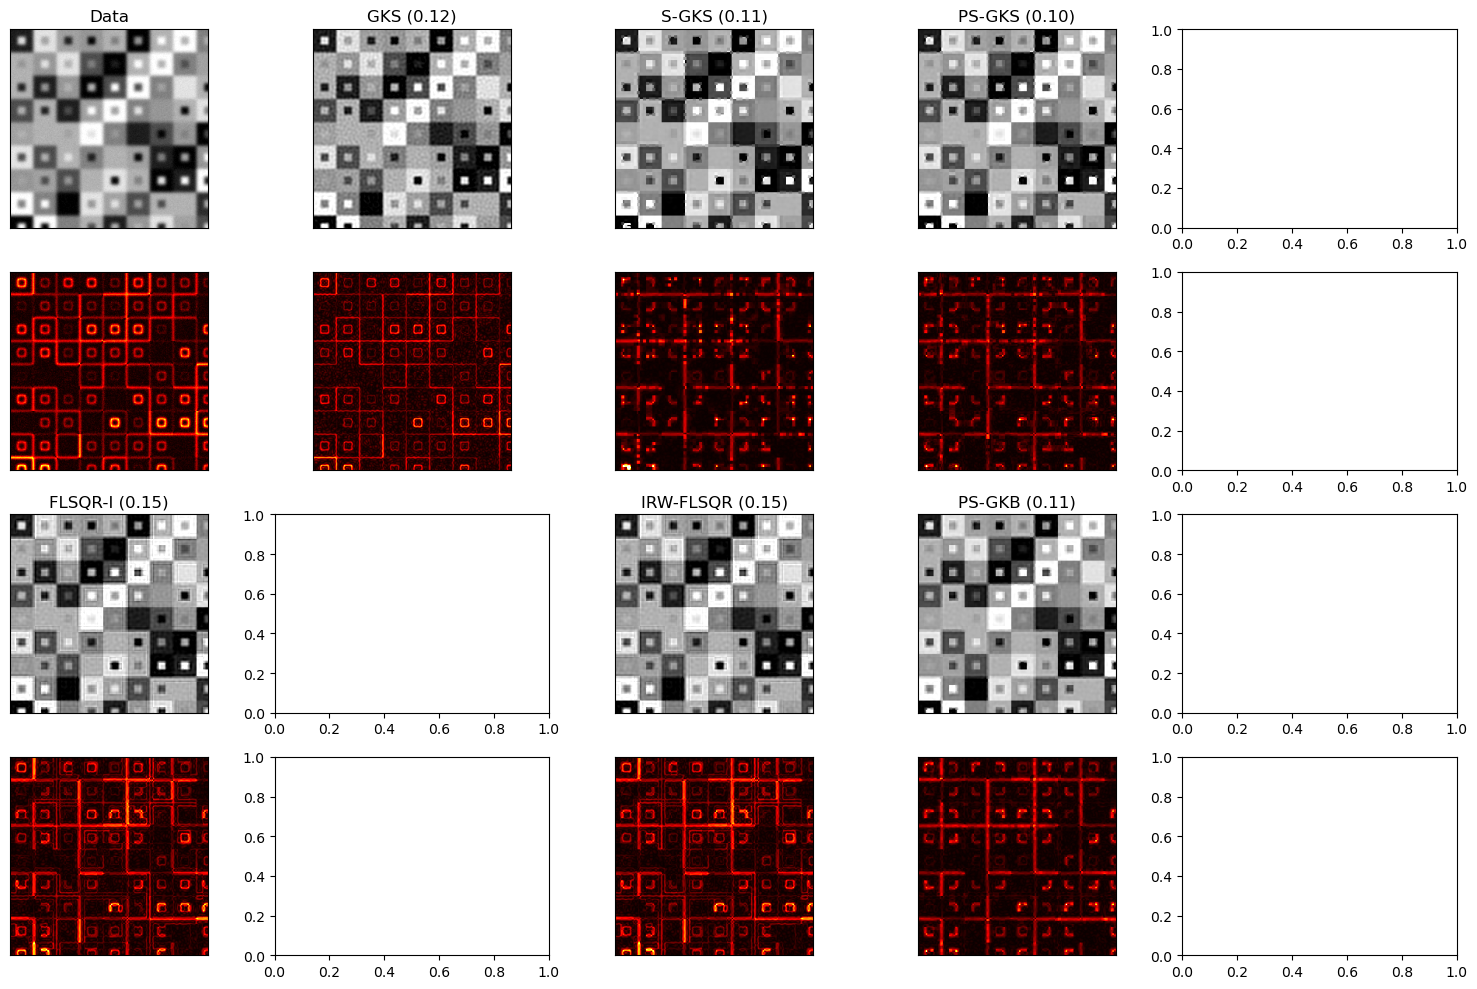

In [72]:
err_cmap = "hot"

vbound = 0.6

fig, axs = plt.subplots(4,5,figsize=(15.3,10))


# Observed
axs[0,0].imshow(b.reshape(img_shape), cmap="gray", vmin=0, vmax=1)
axs[0,0].set_title("Data")
axs[0,0].set_xticks([])
axs[0,0].set_yticks([])

axs[1,0].imshow(np.abs( b.reshape(img_shape) - ground_truth.reshape(img_shape) ), cmap=err_cmap, vmin=0, vmax=vbound)
axs[1,0].set_xticks([])
axs[1,0].set_yticks([])



# Tikhonov
axs[0,1].imshow(vdata["x"].reshape(img_shape), cmap="gray", vmin=0, vmax=1)
rre = vdata["rre_history"][-1]
axs[0,1].set_title(f"GKS ({rre:.2f})")
axs[0,1].set_xticks([])
axs[0,1].set_yticks([])

axs[1,1].imshow(np.abs( vdata["x"].reshape(img_shape) - ground_truth.reshape(img_shape) ), cmap=err_cmap, vmin=0, vmax=vbound)
axs[1,1].set_xticks([])
axs[1,1].set_yticks([])


# S-GKS
axs[0,2].imshow(iassksdata["x"].reshape(img_shape), cmap="gray", vmin=0, vmax=1)
rre = iassksdata["rre_history"][-1]
axs[0,2].set_title(f"S-GKS ({rre:.2f})")
axs[0,2].set_xticks([])
axs[0,2].set_yticks([])
axs[1,2].imshow(np.abs( iassksdata["x"].reshape(img_shape) - ground_truth.reshape(img_shape) ), cmap=err_cmap, vmin=0, vmax=vbound)
axs[1,2].set_xticks([])
axs[1,2].set_yticks([])


# PS-GKS
axs[0,3].imshow(iaspsgkspdata["x"].reshape(img_shape), cmap="gray", vmin=0, vmax=1)
rre = iaspsgkspdata["rre_history"][-1]
axs[0,3].set_title(f"PS-GKS ({rre:.2f})")
axs[0,3].set_xticks([])
axs[0,3].set_yticks([])

axs[1,3].imshow(np.abs( iaspsgkspdata["x"].reshape(img_shape) - ground_truth.reshape(img_shape) ), cmap=err_cmap, vmin=0, vmax=vbound)
axs[1,3].set_xticks([])
axs[1,3].set_yticks([])


# # FGK
# axs[0,4].imshow(fkxdata["x"].reshape(img_shape), cmap="gray", vmin=0, vmax=1)
# rre = mmfkxdata["rre_history"][-1]
# axs[0,4].set_title(f"FGK ({rre:.2f})")
# axs[0,4].set_xticks([])
# axs[0,4].set_yticks([])

# axs[1,4].imshow(np.abs( mmfkxdata["x"].reshape(img_shape) - ground_truth.reshape(img_shape) ), cmap=err_cmap, vmin=0, vmax=vbound)
# axs[1,4].set_xticks([])
# axs[1,4].set_yticks([])



# FLSQR-I
axs[2,0].imshow(iasfk2019Idata["x"].reshape(img_shape), cmap="gray", vmin=0, vmax=1)
rre = iasfk2019Idata["rre_history"][-1]
axs[2,0].set_title(f"FLSQR-I ({rre:.2f})")
axs[2,0].set_xticks([])
axs[2,0].set_yticks([])

axs[3,0].imshow(np.abs( iasfk2019Idata["x"].reshape(img_shape) - ground_truth.reshape(img_shape) ), cmap=err_cmap, vmin=0, vmax=vbound)
axs[3,0].set_xticks([])
axs[3,0].set_yticks([])




# # FLSQR-R
# axs[2,1].imshow(mmfk2019Rdata["x"].reshape(img_shape), cmap="gray", vmin=0, vmax=1)
# rre = mmfk2019Rdata["rre_history"][-1]
# axs[2,1].set_title(f"FLSQR-R ({rre:.2f})")
# axs[2,1].set_xticks([])
# axs[2,1].set_yticks([])

# axs[3,1].imshow(np.abs( mmfk2019Rdata["x"].reshape(img_shape) - ground_truth.reshape(img_shape) ), cmap=err_cmap, vmin=0, vmax=vbound)
# axs[3,1].set_xticks([])
# axs[3,1].set_yticks([])



# FLSQR-W
axs[2,2].imshow(iasfk2019Wdata["x"].reshape(img_shape), cmap="gray", vmin=0, vmax=1)
rre = iasfk2019Wdata["rre_history"][-1]
axs[2,2].set_title(f"IRW-FLSQR ({rre:.2f})")
axs[2,2].set_xticks([])
axs[2,2].set_yticks([])

axs[3,2].imshow(np.abs( iasfk2019Wdata["x"].reshape(img_shape) - ground_truth.reshape(img_shape) ), cmap=err_cmap, vmin=0, vmax=vbound)
axs[3,2].set_xticks([])
axs[3,2].set_yticks([])




# FLSQR-W
axs[2,3].imshow(iasgkbdata["x"].reshape(img_shape), cmap="gray", vmin=0, vmax=1)
rre = iasgkbdata["rre_history"][-1]
axs[2,3].set_title(f"PS-GKB ({rre:.2f})")
axs[2,3].set_xticks([])
axs[2,3].set_yticks([])

axs[3,3].imshow(np.abs( iasgkbdata["x"].reshape(img_shape) - ground_truth.reshape(img_shape) ), cmap=err_cmap, vmin=0, vmax=vbound)
axs[3,3].set_xticks([])
axs[3,3].set_yticks([])




# # PS-GKS restarting
# im = axs[0,5].imshow(mmgkbdata["x"].reshape(img_shape), cmap="gray", vmin=0, vmax=1)
# axs[0,5].set_title("P-GKB")
# axs[0,5].set_xticks([])
# axs[0,5].set_yticks([])
# divider = make_axes_locatable(axs[0,5])
# cax = divider.append_axes("right", size="5%", pad=0.05)
# fig.colorbar(im, cax=cax)

# im = axs[1,5].imshow(np.abs(mmgkbdata["x"].reshape(img_shape) - ground_truth.reshape(img_shape)), cmap=err_cmap, vmin=0, vmax=vbound)
# axs[1,5].set_xticks([])
# axs[1,5].set_yticks([])
# divider = make_axes_locatable(axs[1,5])
# cax = divider.append_axes("right", size="5%", pad=0.00)
# fig.colorbar(im, cax=cax)

fig.tight_layout()

fig.savefig("2d_square_reconstructions_ias.png", dpi=250, bbox_inches=None)
fig.savefig("2d_square_reconstructions_ias.eps", format="eps", dpi=250, bbox_inches=None)


plt.show()

[]

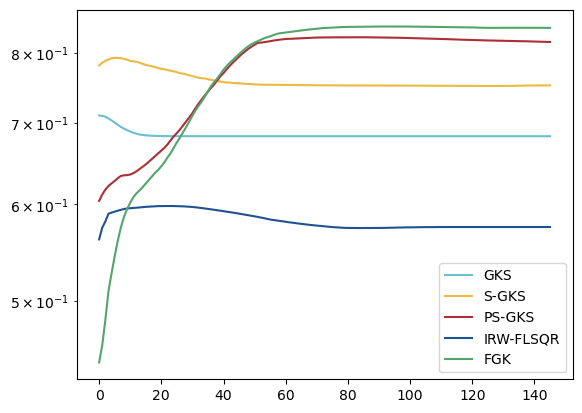

In [79]:
start_idx = 5
# metric = "rre_history"
metric = "ssim_history"

plt.semilogy(vdata[metric][start_idx:], label="GKS")
plt.semilogy(mmsgksdata[metric][start_idx:], label="S-GKS")
plt.semilogy(mmpsgkspdata[metric][start_idx:], label="PS-GKS")
plt.semilogy(mmfk2019Rdata[metric][start_idx:], label="IRW-FLSQR")
plt.semilogy(mmfkxdata[metric][start_idx:], label="FGK")
plt.legend()
plt.plot()

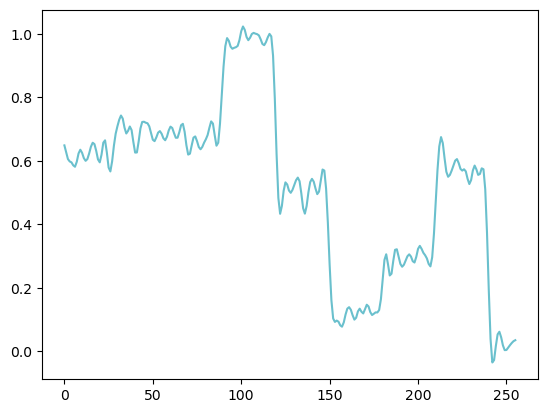

In [91]:
plt.plot(vdata["x"].reshape(img_shape)[125,:] )
# plt.plot(mmsgksdata["x"].reshape(img_shape)[125,:] )
# plt.plot(mmfk2019Rdata["x"].reshape(img_shape)[125,:] )
# plt.plot(mmfkxdata["x"].reshape(img_shape)[125,:] )
# plt.plot(mmpsgkspdata["x"].reshape(img_shape)[125,:] )
# plt.plot(mmgkbdata["x"].reshape(img_shape)[125,:] )

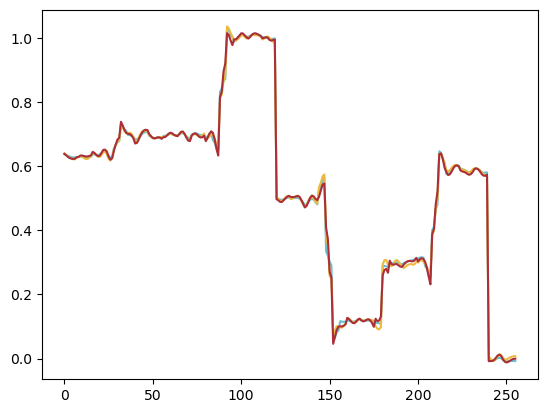

In [94]:
plt.plot(iassksdata["x"].reshape(img_shape)[125,:] )
# plt.plot(iasfk2910Rdata["x"].reshape(img_shape)[125,:] )
# plt.plot(iasfkxdata["x"].reshape(img_shape)[125,:] )
plt.plot(iaspsgkspdata["x"].reshape(img_shape)[125,:] )
plt.plot(iasgkbdata["x"].reshape(img_shape)[125,:] )

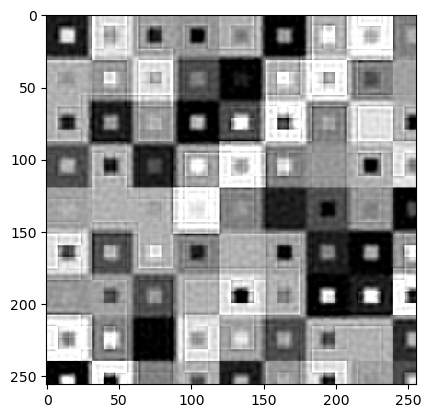

In [71]:
plt.imshow( (iasfkdata["x"]).reshape(img_shape), cmap="gray", vmin=0, vmax=1)
plt.show()

In [92]:
plt.imshow( (iassgksdata["x"]).reshape(img_shape), cmap="gray", vmin=0, vmax=1)
plt.show()

NameError: name 'iassgksdata' is not defined

# Performance

NameError: name 'vdata' is not defined

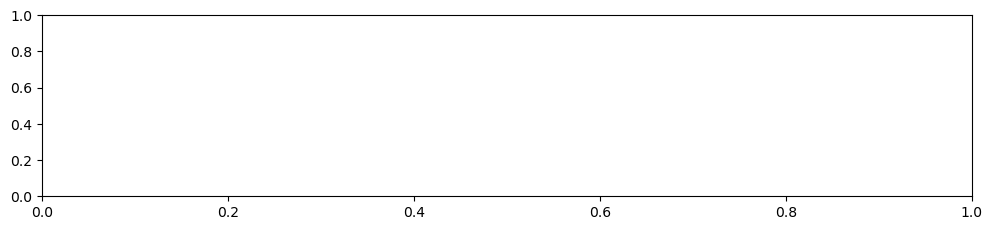

In [24]:
fig = plt.figure(figsize=(12,8) )

gs = gridspec.GridSpec(3, 2, figure=fig)

start_idx = 5
marker = ">"
markerfacecolor = 'none'

ax4 = fig.add_subplot(gs[0, :])
# ax4.semilogy([i for i in range(start_idx, len(vdata["rre_history"]))],  vdata["rre_history"][start_idx:], label="GKS", color="C3", marker=marker, markerfacecolor=markerfacecolor)
# ax4.semilogy([i for i in range(start_idx, len(vdata["rre_history"]))], data["rre_history"][start_idx:], label="S-GKS", color="C5", marker=marker, markerfacecolor=markerfacecolor)
# ax4.semilogy([i for i in range(start_idx, len(vdata["rre_history"]))], pdata["rre_history"][start_idx:], label="PS-GKS", color="C4", marker=marker, markerfacecolor=markerfacecolor)
# ax4.semilogy([i for i in range(start_idx, len(vdata["rre_history"]))], mmfkdata["rre_history"][start_idx:], label="FGK", color="C6", marker=marker, markerfacecolor=markerfacecolor)
# ax4.semilogy([i for i in range(start_idx, len(vdata["rre_history"]))], mmgkbdata["rre_history"][start_idx:], label="P-GKB", color="C1", marker=marker, markerfacecolor=markerfacecolor)
ax4.semilogy([i for i in range(start_idx, len(vdata["rre_history"]))], mmfk2019Idata["rre_history"][start_idx:], label="FLSQR-I", color="C9", marker="o", markerfacecolor=markerfacecolor)
ax4.semilogy([i for i in range(start_idx, len(vdata["rre_history"]))], mmfk2019Rdata["rre_history"][start_idx:], label="FLSQR-I", color="C9", marker="^", markerfacecolor=markerfacecolor)
ax4.semilogy([i for i in range(start_idx, len(vdata["rre_history"]))], mmfk2019Wdata["rre_history"][start_idx:], label="FLSQR-W", color="C9", marker="<", markerfacecolor=markerfacecolor)
ax4.legend()
ax4.set_xlabel("Iteration index")
ax4.set_title("RRE history")



ax3 = fig.add_subplot(gs[1, :])
ax3.semilogy([i for i in range(start_idx, len(vdata["rre_history"]))], vdata["ssim_history"][start_idx:], label="GKS", color="C3", marker=marker, markerfacecolor=markerfacecolor)
ax3.semilogy([i for i in range(start_idx, len(vdata["rre_history"]))], data["ssim_history"][start_idx:], label="S-GKS", color="C5", marker=marker, markerfacecolor=markerfacecolor)
ax3.semilogy([i for i in range(start_idx, len(vdata["rre_history"]))], pdata["ssim_history"][start_idx:], label="PS-GKS", color="C4", marker=marker, markerfacecolor=markerfacecolor)
ax3.semilogy([i for i in range(start_idx, len(vdata["rre_history"]))], mmfkdata["ssim_history"][start_idx:], label="FGK", color="C6", marker=marker, markerfacecolor=markerfacecolor)
ax3.semilogy([i for i in range(start_idx, len(vdata["rre_history"]))], mmgkbdata["ssim_history"][start_idx:], label="P-GKB", color="C1", marker=marker, markerfacecolor=markerfacecolor)
ax3.semilogy([i for i in range(start_idx, len(vdata["rre_history"]))], mmfk2019Idata["ssim_history"][start_idx:], label="FLSQR-I", color="C9", marker="o", markerfacecolor=markerfacecolor)
ax3.semilogy([i for i in range(start_idx, len(vdata["rre_history"]))], mmfk2019Rdata["ssim_history"][start_idx:], label="FLSQR-I", color="C9", marker="^", markerfacecolor=markerfacecolor)
ax3.semilogy([i for i in range(start_idx, len(vdata["rre_history"]))], mmfk2019Wdata["ssim_history"][start_idx:], label="FLSQR-W", color="C9", marker="<", markerfacecolor=markerfacecolor)
ax3.legend()
ax3.set_xlabel("Iteration index")
ax3.set_title("SSIM history")

# ax3 = fig.add_subplot(gs[1, :])
# ax3.semilogy(vdata["haar_history"][start_idx:], label="GKS")
# ax3.semilogy(data["haar_history"][start_idx:], label="S-GKS")
# ax3.semilogy(pdata["haar_history"][start_idx:], label="PS-GKS")
# ax3.semilogy(mmfkdata["haar_history"][start_idx:], label="FGK")
# ax3.semilogy(mmgkbdata["haar_history"][start_idx:], label="P-GKB")
# ax3.legend()


ax1 = fig.add_subplot(gs[2, 0])
ax1.semilogy(vdata["lambda_history"], label="GKS", color="C3")
ax1.semilogy(data["lambda_history"], label="S-GKS", color="C5")
ax1.semilogy(pdata["lambda_history"], label="PS-GKS", color="C4")
ax1.semilogy(mmfkdata["lambda_history"], label="FGK", color="C6")
ax1.semilogy(mmgkbdata["lambda_history"], label="P-GKB", color="C1")
ax1.legend(loc="lower right")
ax1.set_title("History of $\lambda$")
ax1.set_xlabel("Iteration index")



ax2 = fig.add_subplot(gs[2, 1])
ax2.semilogy(vdata["cond_ests"], label="GKS", color="C3")
ax2.semilogy(data["cond_ests"], label="S-GKS", color="C5")
ax2.semilogy(pdata["cond_ests"], label="PS-GKS", color="C4")
ax2.semilogy(mmfkdata["cond_ests"], label="FGK", color="C6")
ax2.semilogy(mmgkbdata["cond_ests"], label="P-GKB", color="C1")
ax2.legend(loc="upper left")
ax2.set_title("History of condition number")
ax2.set_xlabel("Iteration index")

fig.tight_layout()
fig.savefig("2d_camera_performance_mm.png", dpi=250, bbox_inches=None)
fig.savefig("2d_camera_performance_mm.eps", format="eps", dpi=250, bbox_inches=None)


plt.show()

# Reconstruction

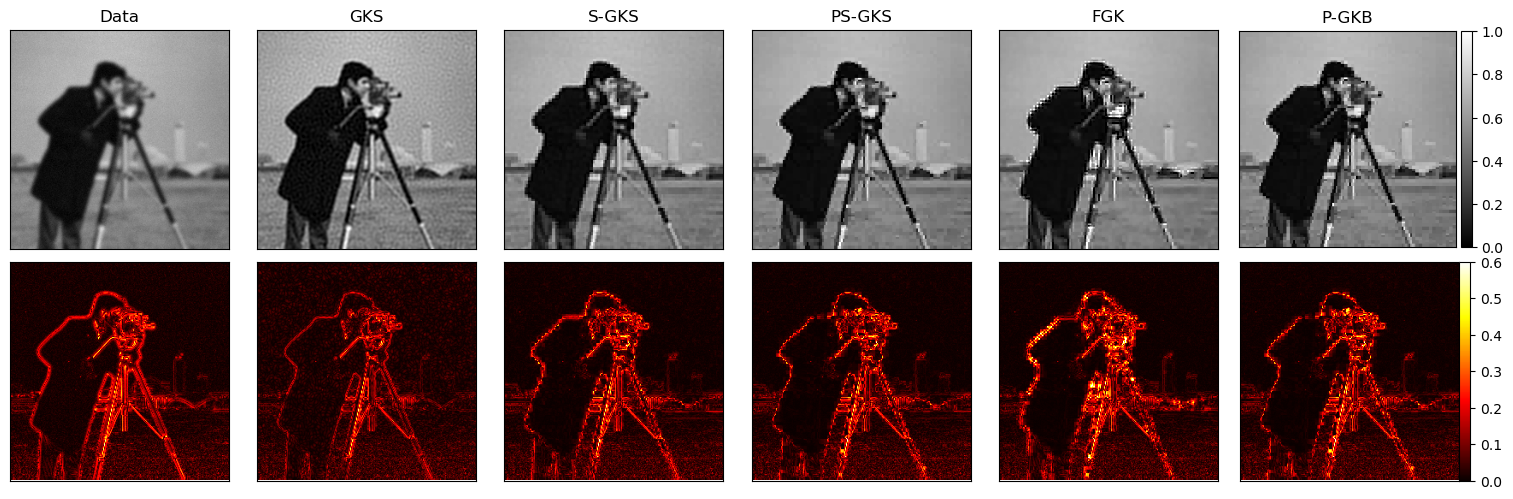

In [239]:
err_cmap = "hot"

vbound = 0.6

fig, axs = plt.subplots(2,6,figsize=(15.3,5))


# Observed
axs[0,0].imshow(b.reshape(img_shape), cmap="gray", vmin=0, vmax=1)
axs[0,0].set_title("Data")
axs[0,0].set_xticks([])
axs[0,0].set_yticks([])

axs[1,0].imshow(np.abs( b.reshape(img_shape) - ground_truth.reshape(img_shape) ), cmap=err_cmap, vmin=0, vmax=vbound)
axs[1,0].set_xticks([])
axs[1,0].set_yticks([])



# Tikhonov
axs[0,1].imshow(vdata["x"].reshape(img_shape), cmap="gray", vmin=0, vmax=1)
axs[0,1].set_title("GKS")
axs[0,1].set_xticks([])
axs[0,1].set_yticks([])

axs[1,1].imshow(np.abs( vdata["x"].reshape(img_shape) - ground_truth.reshape(img_shape) ), cmap=err_cmap, vmin=0, vmax=vbound)
axs[1,1].set_xticks([])
axs[1,1].set_yticks([])


# S-GKS
axs[0,2].imshow(data["x"].reshape(img_shape), cmap="gray", vmin=0, vmax=1)
axs[0,2].set_title("S-GKS")
axs[0,2].set_xticks([])
axs[0,2].set_yticks([])

axs[1,2].imshow(np.abs( data["x"].reshape(img_shape) - ground_truth.reshape(img_shape) ), cmap=err_cmap, vmin=0, vmax=vbound)
axs[1,2].set_xticks([])
axs[1,2].set_yticks([])


# PS-GKS
axs[0,3].imshow(pdata["x"].reshape(img_shape), cmap="gray", vmin=0, vmax=1)
axs[0,3].set_title("PS-GKS")
axs[0,3].set_xticks([])
axs[0,3].set_yticks([])

axs[1,3].imshow(np.abs( pdata["x"].reshape(img_shape) - ground_truth.reshape(img_shape) ), cmap=err_cmap, vmin=0, vmax=vbound)
axs[1,3].set_xticks([])
axs[1,3].set_yticks([])


# FGK
axs[0,4].imshow(mmfkdata["x"].reshape(img_shape), cmap="gray", vmin=0, vmax=1)
axs[0,4].set_title("FGK")
axs[0,4].set_xticks([])
axs[0,4].set_yticks([])

axs[1,4].imshow(np.abs( mmfkdata["x"].reshape(img_shape) - ground_truth.reshape(img_shape) ), cmap=err_cmap, vmin=0, vmax=vbound)
axs[1,4].set_xticks([])
axs[1,4].set_yticks([])



# PS-GKS restarting
im = axs[0,5].imshow(mmgkbdata["x"].reshape(img_shape), cmap="gray", vmin=0, vmax=1)
axs[0,5].set_title("P-GKB")
axs[0,5].set_xticks([])
axs[0,5].set_yticks([])
divider = make_axes_locatable(axs[0,5])
cax = divider.append_axes("right", size="5%", pad=0.05)
fig.colorbar(im, cax=cax)

im = axs[1,5].imshow(np.abs(mmgkbdata["x"].reshape(img_shape) - ground_truth.reshape(img_shape)), cmap=err_cmap, vmin=0, vmax=vbound)
axs[1,5].set_xticks([])
axs[1,5].set_yticks([])
divider = make_axes_locatable(axs[1,5])
cax = divider.append_axes("right", size="5%", pad=0.00)
fig.colorbar(im, cax=cax)

fig.tight_layout()

fig.savefig("2d_camera_reconstructions_mm.png", dpi=250, bbox_inches=None)
fig.savefig("2d_camera_reconstructions_mm.eps", format="eps", dpi=250, bbox_inches=None)


plt.show()

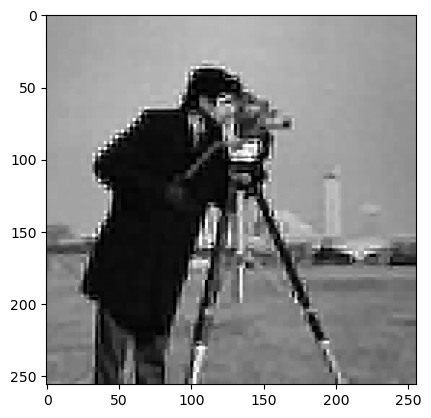

In [11]:
plt.imshow( (mmfkdata["x"]).reshape(img_shape), cmap="gray", vmin=0, vmax=1)
plt.show()

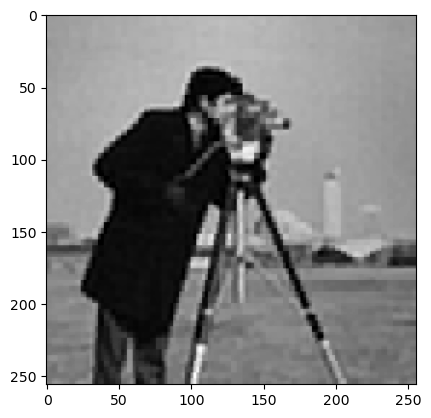

In [11]:
plt.imshow( (mmfk2019Wdata["x"]).reshape(img_shape), cmap="gray", vmin=0, vmax=1)
plt.show()

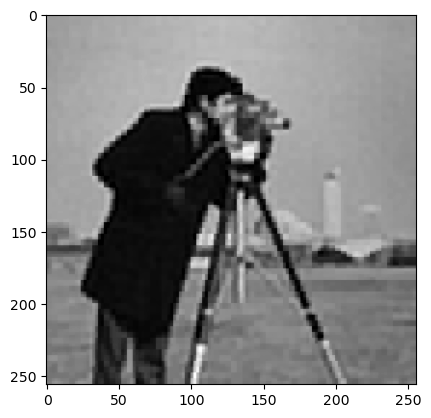

In [12]:
plt.imshow( (mmfk2019Idata["x"]).reshape(img_shape), cmap="gray", vmin=0, vmax=1)
plt.show()

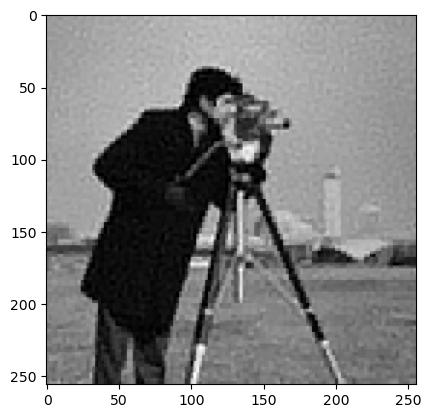

In [14]:
plt.imshow( (mmfk2019Rdata["x"]).reshape(img_shape), cmap="gray", vmin=0, vmax=1)
plt.show()

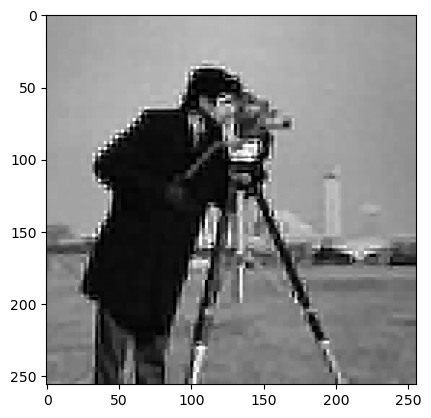

In [15]:
plt.imshow(mmfkdata["x"].reshape(img_shape), cmap="gray", vmin=0, vmax=1)
plt.show()

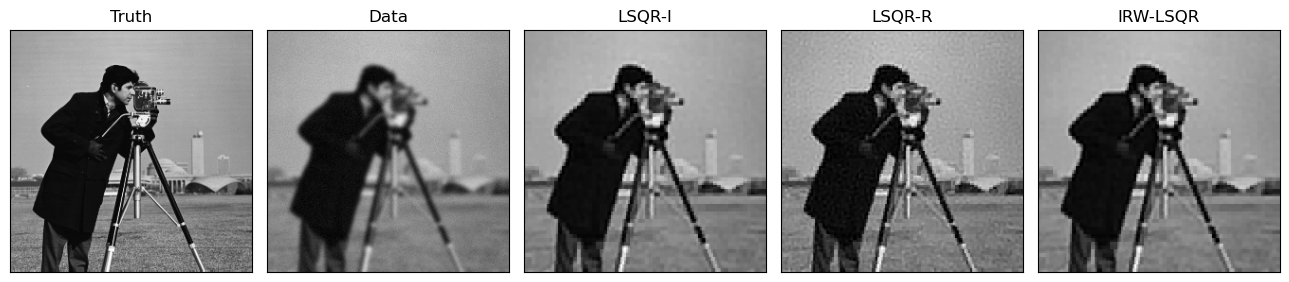

In [48]:
fig, axs = plt.subplots(1,5, figsize=(13,8))

axs[0].imshow(ground_truth.reshape(img_shape), cmap="gray", vmin=0, vmax=1)
axs[0].set_title("Truth")
axs[0].set_xticks([])
axs[0].set_yticks([])

axs[1].imshow((b).reshape(img_shape), cmap="gray", vmin=0, vmax=1)
axs[1].set_title("Data")
axs[1].set_xticks([])
axs[1].set_yticks([])

axs[2].imshow( (mmfk2019Idata["x"]).reshape(img_shape), cmap="gray", vmin=0, vmax=1)
axs[2].set_title("LSQR-I")
axs[2].set_xticks([])
axs[2].set_yticks([])

axs[3].imshow( (mmfk2019Rdata["x"]).reshape(img_shape), cmap="gray", vmin=0, vmax=1)
axs[3].set_title("LSQR-R")
axs[3].set_xticks([])
axs[3].set_yticks([])

axs[4].imshow( (mmfk2019Wdata["x"]).reshape(img_shape), cmap="gray", vmin=0, vmax=1)
axs[4].set_title("IRW-LSQR")
axs[4].set_xticks([])
axs[4].set_yticks([])

fig.tight_layout()

plt.show()

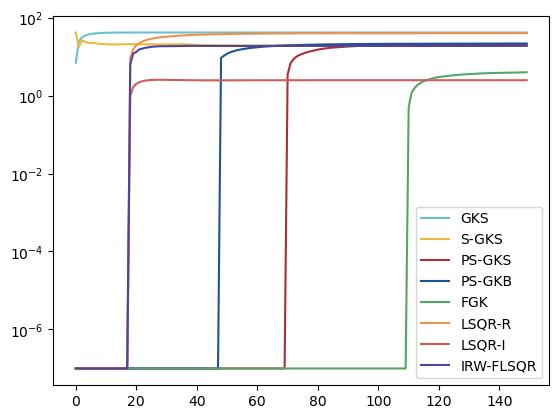

In [54]:
plt.semilogy(vdata["lambda_history"], label="GKS")
plt.semilogy(data["lambda_history"], label="S-GKS")
plt.semilogy(pdata["lambda_history"], label="PS-GKS")
plt.semilogy(mmgkbdata["lambda_history"], label="PS-GKB")
plt.semilogy(mmfkdata["lambda_history"], label="FGK")
plt.semilogy(mmfk2019Rdata["lambda_history"], label="LSQR-R")
plt.semilogy(mmfk2019Idata["lambda_history"], label="LSQR-I")
plt.semilogy(mmfk2019Wdata["lambda_history"], label="IRW-FLSQR")
plt.legend()
plt.show()

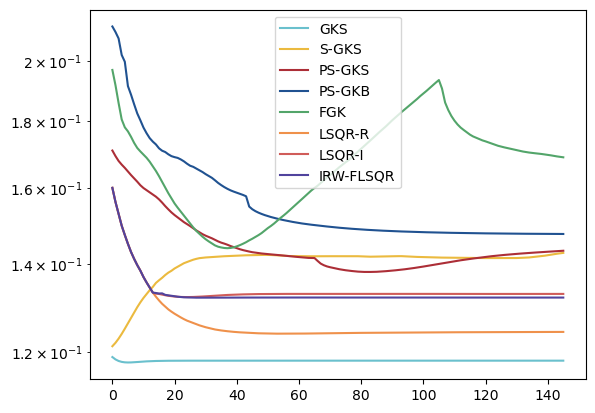

In [59]:
start_idx = 5
plt.semilogy(vdata["rre_history"][start_idx:], label="GKS")
plt.semilogy(data["rre_history"][start_idx:], label="S-GKS")
plt.semilogy(pdata["rre_history"][start_idx:], label="PS-GKS")
plt.semilogy(mmgkbdata["rre_history"][start_idx:], label="PS-GKB")
plt.semilogy(mmfkdata["rre_history"][start_idx:], label="FGK")
plt.semilogy(mmfk2019Rdata["rre_history"][start_idx:], label="LSQR-R")
plt.semilogy(mmfk2019Idata["rre_history"][start_idx:], label="LSQR-I")
plt.semilogy(mmfk2019Wdata["rre_history"][start_idx:], label="IRW-FLSQR")
plt.legend()
plt.show()

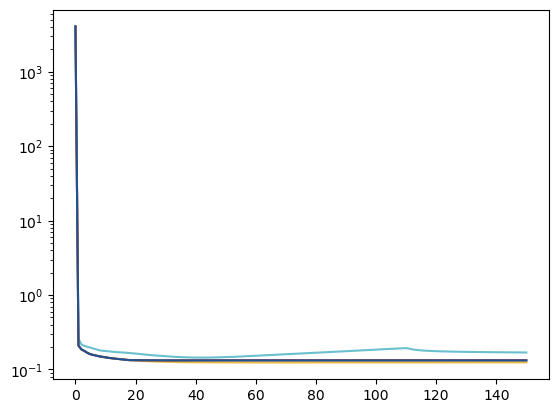

In [32]:
plt.semilogy(mmfkdata["rre_history"])
plt.semilogy(mmfk2019Rdata["rre_history"])
plt.semilogy(mmfk2019Idata["rre_history"])
plt.semilogy(mmfk2019Wdata["rre_history"])
plt.show()

# Basis vectors

In [154]:
np.amax(np.abs(data["V"][:,:]))

0.1890169249359265

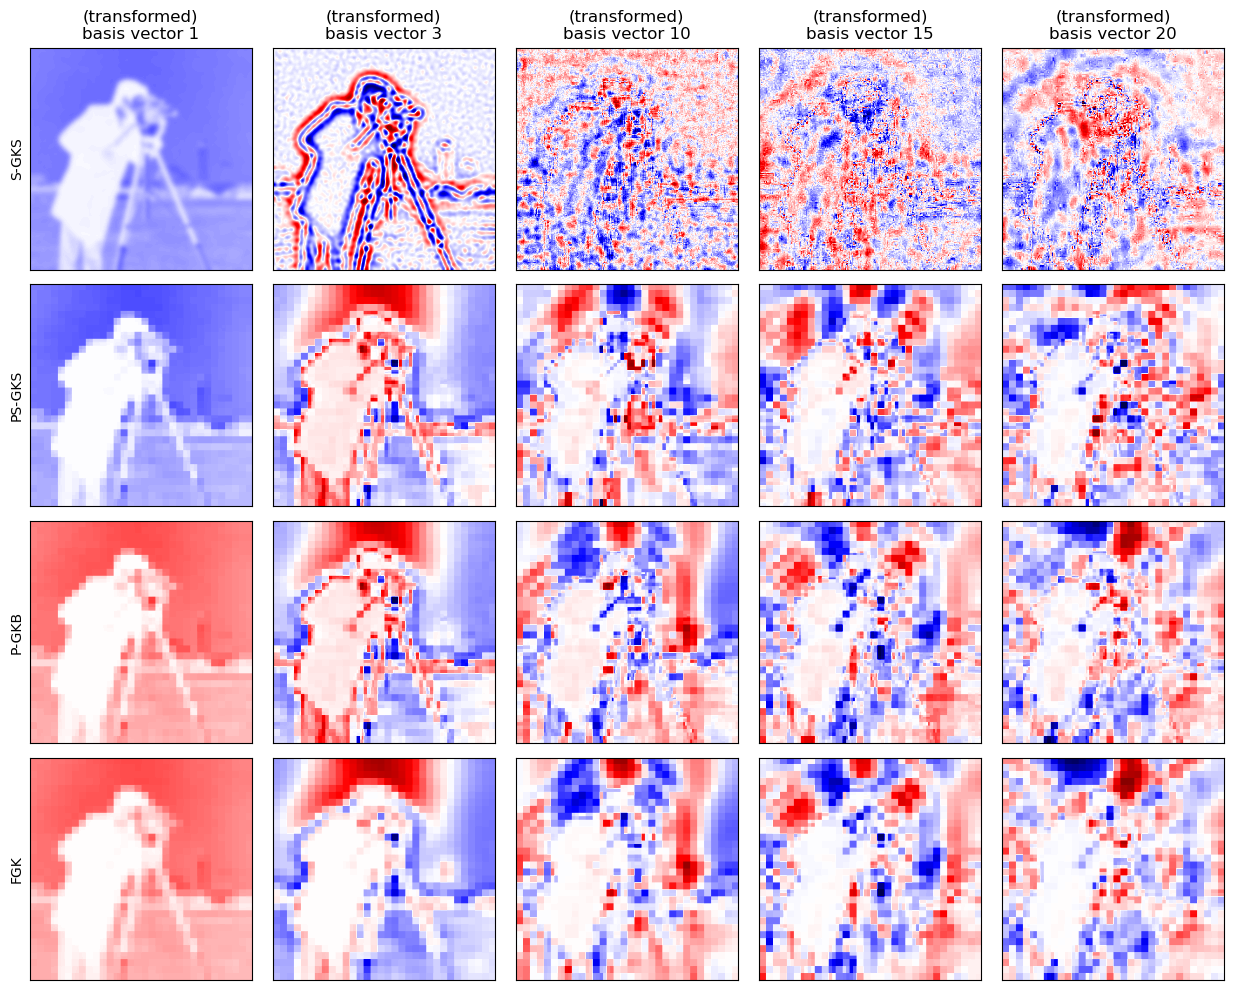

In [170]:
cmap = "seismic"
vbound = 0.1*0.189

kks = [0, 2, 9, 14, 19]

fig, axs = plt.subplots(4,5,figsize=(12.5,10))

for j, kk in enumerate(kks):

    axs[0,j].imshow(data["V"][:,kk].reshape(img_shape), cmap=cmap, vmin=-vbound, vmax=vbound)
    axs[0,j].set_title(f"S-GKS basis vector {kk+1}")
    axs[0,j].set_xticks([])
    axs[0,j].set_yticks([])
    if j == 0:
        axs[0,0].set_ylabel(f"S-GKS")
    axs[0,j].set_title(f"(transformed)\nbasis vector {kk+1}")


for j, kk in enumerate(kks):

    axs[1,j].imshow( ( (pdata["Lopinv"] @ pdata["V"][:,kk])/np.linalg.norm(pdata["Lopinv"] @ pdata["V"][:,kk]) ).reshape(img_shape), cmap=cmap, vmin=-vbound, vmax=vbound)
    axs[1,j].set_xticks([])
    axs[1,j].set_yticks([])
    if j == 0:
        axs[1,j].set_ylabel(f"PS-GKS")


for j, kk in enumerate(kks):

    axs[2,j].imshow( ( (mmgkbdata["Lopinv"] @ mmgkbdata["V"][:,kk])/np.linalg.norm(mmgkbdata["Lopinv"] @ mmgkbdata["V"][:,kk]) ).reshape(img_shape), cmap=cmap, vmin=-vbound, vmax=vbound)
    axs[2,j].set_xticks([])
    axs[2,j].set_yticks([])
    if j == 0:
        axs[2,j].set_ylabel(f"P-GKB")



for j, kk in enumerate(kks):

    axs[3,j].imshow( ( mmfkdata["Z"][:,kk]/np.linalg.norm(mmfkdata["Z"][:,kk]) ).reshape(img_shape), cmap=cmap, vmin=-vbound, vmax=vbound)
    axs[3,j].set_xticks([])
    axs[3,j].set_yticks([])
    if j == 0:
        axs[3,j].set_ylabel(f"FGK")


fig.tight_layout()

fig.savefig("2d_camera_basis_vectors_mm.png", dpi=250, bbox_inches=None)
fig.savefig("2d_camera_basis_vectors_mm.eps", format="eps", dpi=250, bbox_inches=None)


plt.show()

NameError: name 'resdata' is not defined

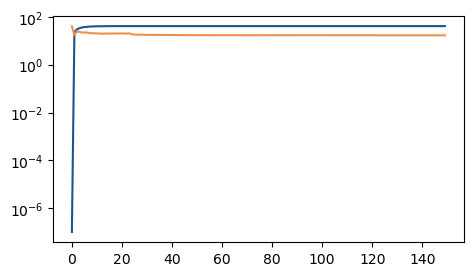

In [20]:
fig = plt.figure(figsize=(18,10))

gs = gridspec.GridSpec(3, 3, figure=fig)

ax1 = fig.add_subplot(gs[2, 2])
ax1.semilogy(vdata["lambda_history"], label="GKS", color="C3")
ax1.semilogy(data["lambda_history"], label="S-GKS", color="C5")
ax1.semilogy(resdata["lambda_history"], label="S-GKS (restarting)", color="C5", ls="--")
ax1.semilogy(recdata["lambda_history"], label="S-GKS (recycling)", color="C5", ls=":")
ax1.semilogy(pdata["lambda_history"], label="PS-GKS", color="C4")
ax1.semilogy(respdata["lambda_history"], label="PS-GKS (restarting)", color="C4", ls="--")
ax1.set_title("History of $\\lambda$")
ax1.set_xlabel("Iteration index")
ax1.legend()


ax2 = fig.add_subplot(gs[0, 0])
ax2.semilogy(vdata["rre_history"], label="GKS", color="C3")
ax2.semilogy(data["rre_history"], label="S-GKS", color="C5")
ax2.semilogy(resdata["rre_history"], label="S-GKS (restarting)", color="C5", ls="--")
ax2.semilogy(recdata["rre_history"], label="S-GKS (recycling)", color="C5", ls=":")
ax2.semilogy(pdata["rre_history"], label="PS-GKS", color="C4")
ax2.semilogy(respdata["rre_history"], label="PS-GKS (restarting)", color="C4", ls="--")
ax2.set_title("RRE")
ax2.set_xlabel("Iteration index")
ax2.legend()


ax3 = fig.add_subplot(gs[0, 1])
ax3.semilogy(vdata["ssim_history"], label="GKS")
ax3.semilogy(data["ssim_history"], label="S-GKS", color="C5")
ax3.semilogy(resdata["ssim_history"], label="S-GKS (restarting)", color="C5", ls="--")
ax3.semilogy(recdata["ssim_history"], label="S-GKS (recycling)", color="C5", ls=":")
ax3.semilogy(pdata["ssim_history"], label="PS-GKS", color="C4")
ax3.semilogy(respdata["ssim_history"], label="PS-GKS (restarting)", color="C4", ls="--")
ax3.set_title("SSIM")
ax3.set_xlabel("Iteration index")
ax3.legend()



ax7 = fig.add_subplot(gs[0, 2])
ax7.semilogy(vdata["haar_history"], label="GKS")
ax7.semilogy(data["haar_history"], label="S-GKS", color="C5")
ax7.semilogy(resdata["haar_history"], label="S-GKS (restarting)", color="C5", ls="--")
ax7.semilogy(recdata["haar_history"], label="S-GKS (recycling)", color="C5", ls=":")
ax7.semilogy(pdata["haar_history"], label="PS-GKS", color="C4")
ax7.semilogy(respdata["haar_history"], label="PS-GKS (restarting)", color="C4", ls="--")
ax7.set_title("HaarPSI")
ax7.set_xlabel("Iteration index")
ax7.legend()




ax5 = fig.add_subplot(gs[1, :2]) 
ax5.semilogy(1.0/resdata["w"][:int(len(resdata["w"])/2)].reshape(img_shape)[128,:], label="S-GKS (restarting)", color="C5", ls="--")
ax5.semilogy(1.0/respdata["w"][:int(len(resdata["w"])/2)].reshape(img_shape)[128,:], label="PS-GKS (restarting)", color="C4", ls="--")
ax5.set_xlabel("Horizontal cross section at index 128")
ax5.set_title("$1/w$")
ax5.legend()



ax6 = fig.add_subplot(gs[1, 2])
ax6.semilogy(vdata["cond_ests"], label="GKS", color="C3")
ax6.semilogy(data["cond_ests"], label="S-GKS", color="C5")
ax6.semilogy(resdata["cond_ests"], label="S-GKS (restarting)", color="C5", ls="--")
ax6.semilogy(recdata["cond_ests"], label="S-GKS (recycling)", color="C5", ls=":")
ax6.semilogy(pdata["cond_ests"], label="PS-GKS", color="C2")
ax6.semilogy(respdata["cond_ests"], label="PS-GKS (restarting)", color="C4", ls="--")
ax6.set_title("Condition number")
ax6.set_xlabel("Iteration index")
ax6.legend()





ax4 = fig.add_subplot(gs[2, :2]) 
ax4.plot(x_true.reshape(img_shape)[128,:], label="Ground truth", color="k", alpha=0.8, lw=0.5)
ax4.plot(vdata["x"].reshape(img_shape)[128,:], label="GKS", color="C3", ls="--")
ax4.plot(resdata["x"].reshape(img_shape)[128,:], label="S-GKS (restarting)", color="C5", ls="--")
ax4.plot(respdata["x"].reshape(img_shape)[128,:], label="PS-GKS (restarting)", color="C4", ls="--")
ax4.set_xlabel("Horizontal cross section at index 128")
ax4.legend()



fig.tight_layout()
# fig.savefig("2d_shepp_performance_mm.png", dpi=250, bbox_inches=None)
# fig.savefig("2d_shepp_performance_mm.eps", format="eps", dpi=250, bbox_inches=None)

plt.show()

# Other plots

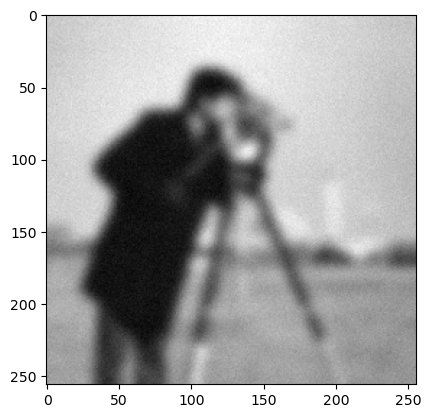

In [135]:
plt.imshow(b.reshape(img_shape), cmap="gray")
plt.show()

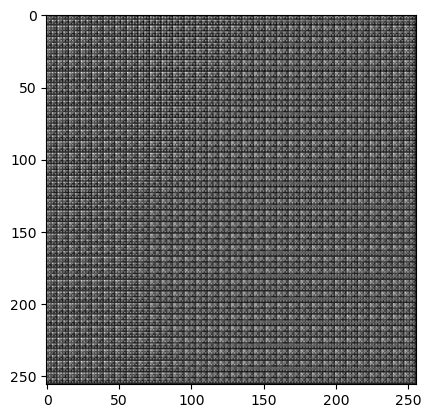

In [136]:
plt.imshow( (L.T @ b).reshape(img_shape), cmap="gray")
plt.show()

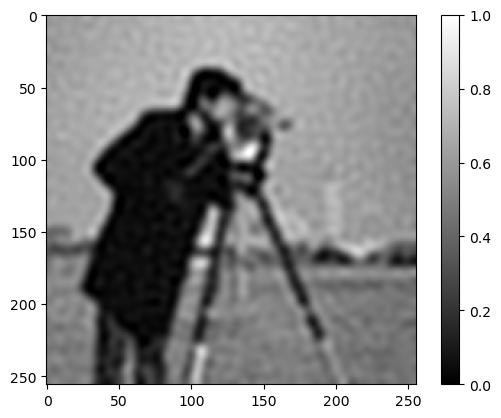

In [116]:
plt.imshow(vdata["x"].reshape(img_shape), cmap="gray", vmin=0.0, vmax=1.0)
plt.colorbar()
plt.show()

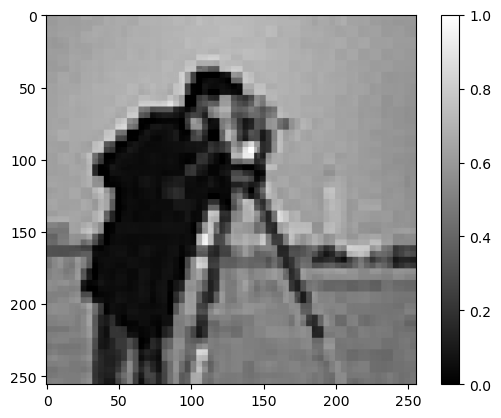

In [117]:
plt.imshow(data["x"].reshape(img_shape), cmap="gray", vmin=0.0, vmax=1.0)
plt.colorbar()
plt.show()

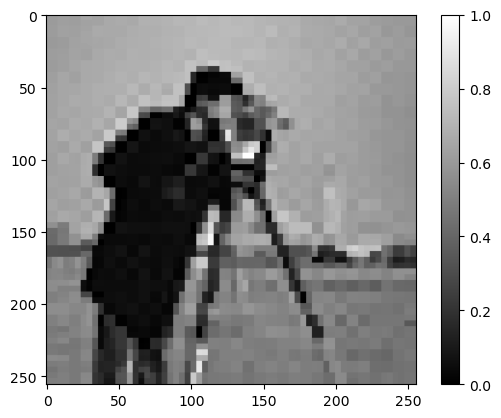

In [118]:
plt.imshow(pdata["x"].reshape(img_shape), cmap="gray", vmin=0.0, vmax=1.0)
plt.colorbar()
plt.show()

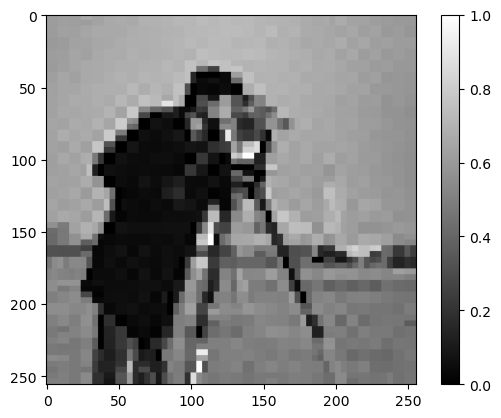

In [119]:
plt.imshow(mmgkbdata["x"].reshape(img_shape), cmap="gray", vmin=0.0, vmax=1.0)
plt.colorbar()
plt.show()

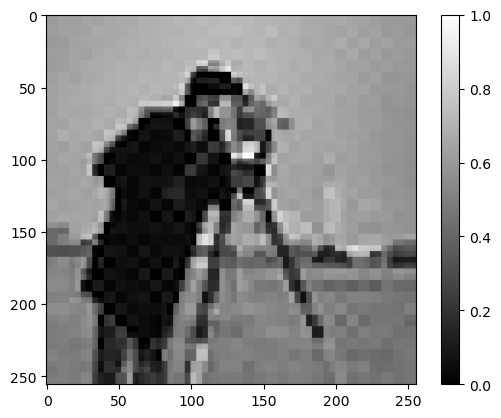

In [120]:
plt.imshow(mmfkdata["x"].reshape(img_shape), cmap="gray", vmin=0.0, vmax=1.0)
plt.colorbar()
plt.show()

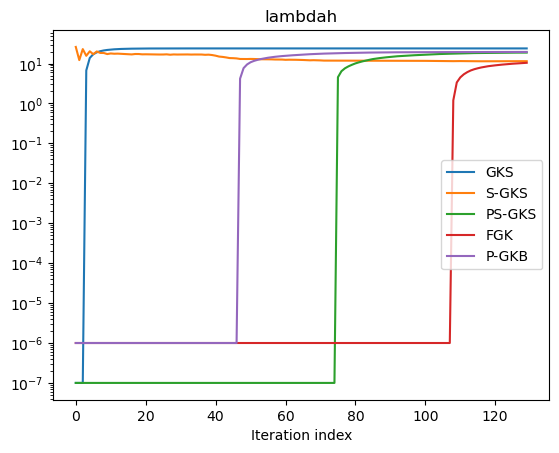

In [121]:
plt.semilogy(vdata["lambda_history"], label="GKS")
plt.semilogy(data["lambda_history"], label="S-GKS")
# plt.semilogy(data_opt["rre_history"], label="S-GKS (optimal)", ls="--", alpha=0.7)
plt.semilogy(pdata["lambda_history"], label="PS-GKS")
plt.semilogy(mmfkdata["lambda_history"], label="FGK")
plt.semilogy(mmgkbdata["lambda_history"], label="P-GKB")
# plt.semilogy(pdata_opt["rre_history"], label="PS-GKS (optimal)", ls="--", alpha=0.7)
#plt.semilogy(rdata["rre_history"], label="Restarted", ls="--", alpha=0.7)
plt.title("lambdah")
plt.xlabel("Iteration index")
plt.legend()
plt.show()

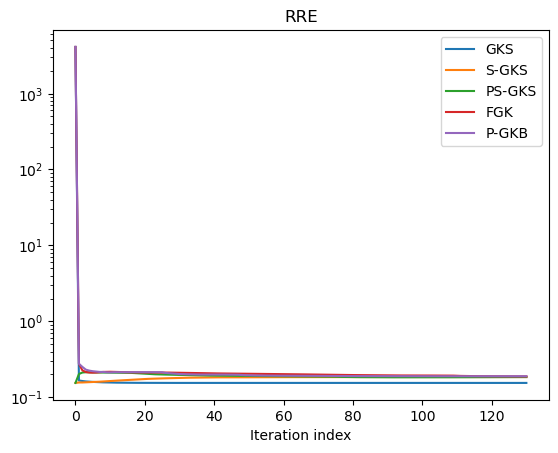

In [122]:
plt.semilogy(vdata["rre_history"], label="GKS")
plt.semilogy(data["rre_history"], label="S-GKS")
# plt.semilogy(data_opt["rre_history"], label="S-GKS (optimal)", ls="--", alpha=0.7)
plt.semilogy(pdata["rre_history"], label="PS-GKS")
plt.semilogy(mmfkdata["rre_history"], label="FGK")
plt.semilogy(mmgkbdata["rre_history"], label="P-GKB")
# plt.semilogy(pdata_opt["rre_history"], label="PS-GKS (optimal)", ls="--", alpha=0.7)
#plt.semilogy(rdata["rre_history"], label="Restarted", ls="--", alpha=0.7)
plt.title("RRE")
plt.xlabel("Iteration index")
plt.legend()
plt.show()

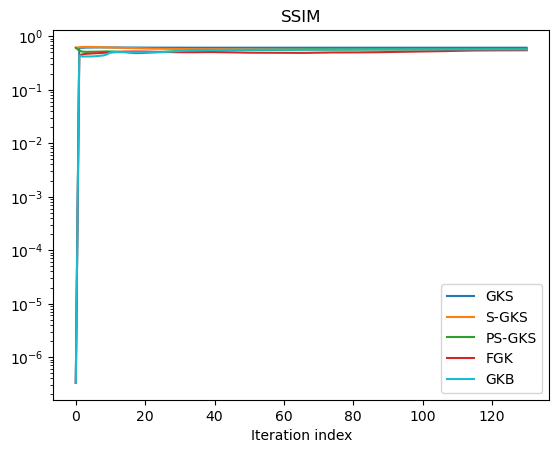

In [125]:
plt.semilogy(vdata["ssim_history"], label="GKS")
plt.semilogy(data["ssim_history"], label="S-GKS")
# plt.semilogy(data_opt["rre_history"], label="S-GKS (optimal)", ls="--", alpha=0.7)
plt.semilogy(pdata["ssim_history"], label="PS-GKS")
plt.semilogy(mmfkdata["ssim_history"], label="FGK")
# plt.semilogy(pdata_opt["rre_history"], label="PS-GKS (optimal)", ls="--", alpha=0.7)
#plt.semilogy(rdata["rre_history"], label="Restarted", ls="--", alpha=0.7)
plt.semilogy(mmgkbdata["ssim_history"], label="GKB", color="C9")
plt.title("SSIM")
plt.xlabel("Iteration index")
plt.legend()
plt.show()

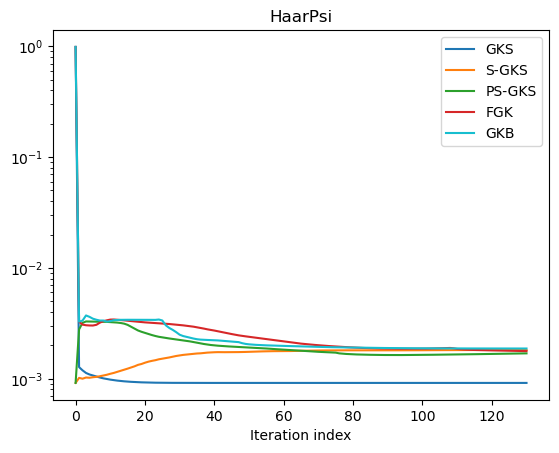

In [126]:
plt.semilogy(1-vdata["haar_history"], label="GKS")
plt.semilogy(1-data["haar_history"], label="S-GKS")
# plt.semilogy(data_opt["rre_history"], label="S-GKS (optimal)", ls="--", alpha=0.7)
plt.semilogy(1-pdata["haar_history"], label="PS-GKS")
plt.semilogy(1-mmfkdata["haar_history"], label="FGK")
# plt.semilogy(pdata_opt["rre_history"], label="PS-GKS (optimal)", ls="--", alpha=0.7)
#plt.semilogy(rdata["rre_history"], label="Restarted", ls="--", alpha=0.7)
plt.semilogy(1-mmgkbdata["haar_history"], label="GKB", color="C9")
plt.title("HaarPsi")
plt.xlabel("Iteration index")
plt.legend()
plt.show()

In [24]:
pdata["haar_history"]

array([0.99977895, 0.99893879, 0.99877378, 0.99870822, 0.99871015,
       0.9987684 , 0.99883229, 0.99887182, 0.99890467, 0.99893616,
       0.99896992, 0.99899804, 0.99902043, 0.99904554, 0.99907053,
       0.99909251, 0.99911082, 0.99912711, 0.99914394, 0.99916236,
       0.99918311, 0.99920906, 0.99923647, 0.99926293, 0.99928414,
       0.9993028 , 0.99932018, 0.99933764, 0.99935618, 0.99937194,
       0.99938765, 0.99940613, 0.99942366, 0.99944045, 0.99945714,
       0.99947115, 0.99948362, 0.99949556, 0.99950773, 0.99951852,
       0.99952721, 0.99953537, 0.99954417, 0.99955255, 0.99956083,
       0.99956818, 0.99957536, 0.99958231, 0.9995889 , 0.99959529,
       0.99960063, 0.99960472, 0.99960906, 0.99961346, 0.99961734,
       0.99962098, 0.99962459, 0.99962742, 0.99962972, 0.9996319 ,
       0.99963382, 0.99963526, 0.99963669, 0.99963862, 0.99964097,
       0.99964298, 0.99964476, 0.99964625, 0.99964718, 0.99964826,
       0.99965394, 0.99966057, 0.99966447, 0.99966765, 0.99967

In [25]:
vdata["haar_history"]

array([9.31203851e-04, 9.99680055e-01, 9.99707518e-01, 9.99728855e-01,
       9.99744216e-01, 9.99755268e-01, 9.99762842e-01, 9.99768336e-01,
       9.99772198e-01, 9.99774815e-01, 9.99776571e-01, 9.99777668e-01,
       9.99778344e-01, 9.99778713e-01, 9.99778885e-01, 9.99778956e-01,
       9.99778968e-01, 9.99778972e-01, 9.99778982e-01, 9.99779013e-01,
       9.99779031e-01, 9.99779029e-01, 9.99779020e-01, 9.99779011e-01,
       9.99779003e-01, 9.99778992e-01, 9.99778986e-01, 9.99778977e-01,
       9.99778971e-01, 9.99778966e-01, 9.99778962e-01, 9.99778960e-01,
       9.99778961e-01, 9.99778962e-01, 9.99778961e-01, 9.99778960e-01,
       9.99778958e-01, 9.99778957e-01, 9.99778955e-01, 9.99778954e-01,
       9.99778953e-01, 9.99778952e-01, 9.99778951e-01, 9.99778951e-01,
       9.99778951e-01, 9.99778951e-01, 9.99778951e-01, 9.99778951e-01,
       9.99778951e-01, 9.99778951e-01, 9.99778951e-01, 9.99778951e-01,
       9.99778951e-01, 9.99778951e-01, 9.99778951e-01, 9.99778951e-01,
      

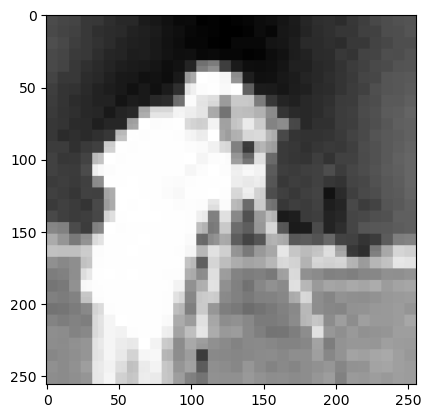

In [127]:
plt.imshow( (pdata["Lopinv"] @ pdata["V"][:,0]).reshape(img_shape) , cmap="gray")
plt.show()

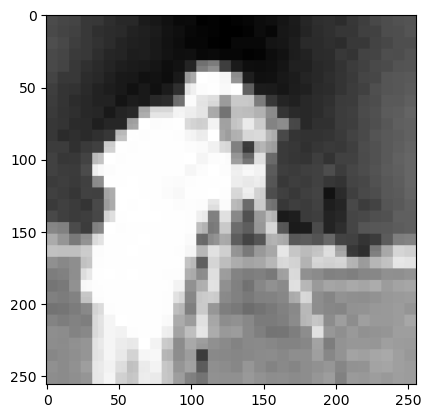

In [128]:
plt.imshow( (pdata["Lopinv"] @ pdata["V"][:,0]).reshape(img_shape) , cmap="gray")
plt.show()

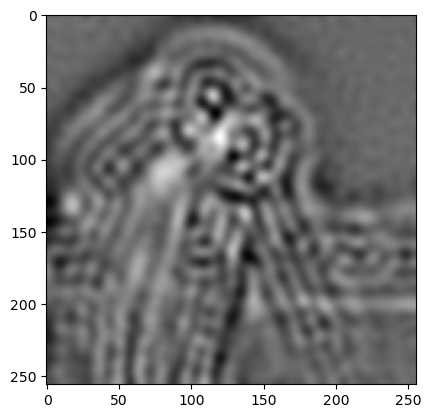

In [129]:
plt.imshow( (vdata["V"][:,5]).reshape(img_shape) , cmap="gray")
plt.show()

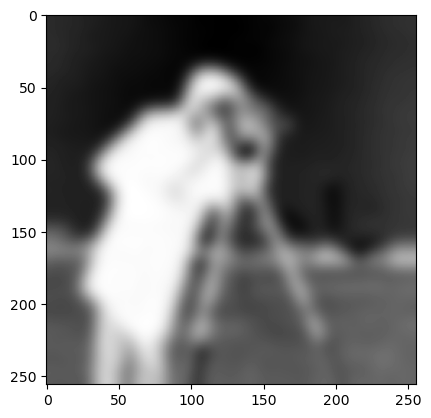

In [130]:
plt.imshow( (data["V"][:,0]).reshape(img_shape) , cmap="gray")
plt.show()

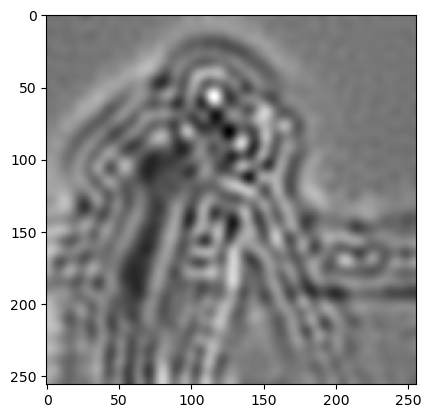

In [131]:
plt.imshow( (data["V"][:,4]).reshape(img_shape) , cmap="gray")
plt.show()

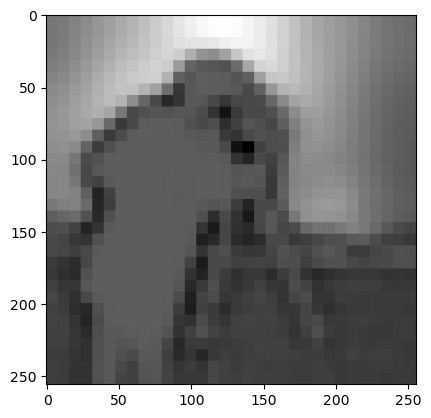

In [132]:
plt.imshow( (mmfkdata["Z"][:,1]).reshape(img_shape) , cmap="gray")
plt.show()

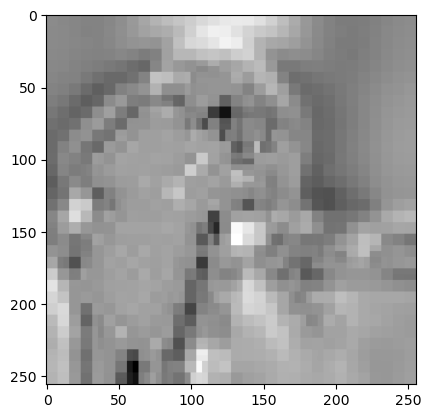

In [133]:
plt.imshow( (mmgkbdata["Lopinv"] @ ( (mmgkbdata["V"][:,4]) ) ).reshape(img_shape) , cmap="gray")
plt.show()

In [134]:
mmgkbdata.keys()

dict_keys(['x', 'V', 'U', 'B', 'w', 'Lopinv', 'lambda_history', 'cond_ests', 'rre_history', 'ssim_history', 'haar_history'])